# Week 6 - DX 799 mod C3 Deb Halder 2026 Fall - Phishing Email Detection- Dataset 1

**Objective:** compare **Decision Tree → Random Forest with bootstrap bagging →
AdaBoost** using the same **5,000 TF-IDF feature cap plus nine engineered counts**.
Keep the existing corpus preparation, NLTK-only stopwords, grouped split, and
full-corpus log1p count-feature EDA. All three families share one reporting format.

**Execution status:** Sections 5–6 use `corpus_eda`to do inivariate and Bivariate analysis.

1. Sections 1–8: read, clean, deduplicate, split, and prepare TF-IDF + raw counts.
   EDA uses a full corpus copy with nine log1p counts; model inputs retain raw counts.
2. Section 9: shared preprocessing, tuning, evaluation, and reporting methods.
3. Sections 10–12: define decision tree, random forest with bagging, and AdaBoost,
   in that order, with quick and expanded hyperparameter options.
4. Section 13: tune each family on identical grouped training folds; choose each
   family's best configuration by mean validation phishing F1 and refit it once.
5. Section 14: display **one combined results DataFrame**, including CV fit time,
   followed by the best configuration for each classifier.
6. Section 15: evaluate the selected models on the holdout and plot full-training
   fit time, classification error, confusion matrices, ROC-AUC and PR curves.
7. Section 16: show hyperparameter plots. Section 17 explains how to interpret
   the tuning/performance results once measured.

Safe=0 and Phishing=1. Vocabulary and IDF are refitted inside each CV training
fold; raw count features need no scaling for these tree-based methods. Labels,
group hashes, and source metadata are excluded from predictors. No threshold
optimization is implemented. Each method documents its inputs and return types.

Dataset: https://www.kaggle.com/datasets/subhajournal/phishingemails.



## 1. Imports and configuration

`MAX_FEATURES_TFIDF` controls the vocabulary cap, not a guaranteed feature counts and bigrams capture individual
words and adjacent two-word phrases. Terms must appear in at least five training emails. 

In [1]:
# Load text-processing, sparse-matrix, plotting, and splitting dependencies.
# Keep dataset/feature settings in one place so preparation and modeling agree.

import hashlib
import html
import re
from collections import Counter
from html.parser import HTMLParser
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedGroupKFold
from IPython.display import display

# Reuse one seed for split and sample reproducibility; max_features is a vocabulary cap.
# min_df removes very rare terms; (1, 2) includes individual words and two-word phrases.
RANDOM_STATE = 42
DATA_PATH = Path('./dataset/phishing_email_1_dataset/Phishing_Email.csv')
TEXT_COLUMN = 'word_text'  # TF-IDF filters the shared NLTK stopwords from this text view.
TARGET_COLUMN = 'label'
MAX_FEATURES_TFIDF = 5000
MIN_DF = 5
NGRAM_RANGE = (1, 2)  # use 1 and 2 word phrases for TF-IDF features; (1, 1) would be single words only

sns.set_theme(style='whitegrid')
pd.set_option('display.max_colwidth', 70)

# Reuse installed NLTK data; download only a missing resource.
for resource, package in [
    ('corpora/stopwords', 'stopwords'),
    ('tokenizers/punkt_tab/english/', 'punkt_tab'),
]:
    try:
        nltk.data.find(resource)
    except LookupError:
        if not nltk.download(package, quiet=True):
            raise RuntimeError(f'Could not install the NLTK resource: {package}')


## 2. Download and read the original data

Download `subhajournal/phishingemails` with KaggleHub and save `Phishing_Email.csv`
to `DATA_PATH`: `./dataset/phishing_email_1_dataset/Phishing_Email.csv`.
The download cell uses a temporary folder, copies the CSV to the project folder,
loads it into `df_phishing_email`, and automatically removes the temporary files.
Running it again downloads the dataset and replaces the local CSV.

The notebook environment needs `kagglehub` with `output_dir` support. If needed,
install or update it with `%pip install -U kagglehub` in a separate cell.

Keep the original email text available for URL counts and text cleaning. Do not
remove stopwords or delete raw text in place. The reused corpus method below
handles empty records, exact duplicates, and conflicting labels.


In [2]:
import shutil
from tempfile import TemporaryDirectory

import kagglehub

destination_dir = DATA_PATH.parent
destination_dir.mkdir(parents=True, exist_ok=True)
saved_file = DATA_PATH

# Download into a temporary folder and remove it automatically after copying/loading.
with TemporaryDirectory(prefix="phishingemails-") as temporary_dir:
    download_path = Path(
        kagglehub.dataset_download(
            "subhajournal/phishingemails",
            output_dir=temporary_dir,
        )
    )

    # Select the expected CSV so an unrelated file cannot become the training data.
    csv_files = sorted(download_path.rglob("*.csv"))
    if not csv_files:
        raise FileNotFoundError("No CSV file was found in the Kaggle download.")
    matching_files = [file for file in csv_files if file.name == DATA_PATH.name]
    if len(matching_files) != 1:
        raise FileNotFoundError(
            f"Expected exactly one {DATA_PATH.name} in the Kaggle download; "
            f"found {[str(file.relative_to(download_path)) for file in csv_files]}."
        )
    csv_file = matching_files[0]

    shutil.copy2(csv_file, saved_file)
    df_phishing_email = pd.read_csv(saved_file)
    print("Loaded df_phishing_email from:", saved_file)
    print("Shape:", df_phishing_email.shape)

print("Deleted temporary download folder:", temporary_dir)


100%|██████████| 18.0M/18.0M [00:00<00:00, 38.9MB/s]

Extracting files...


Loaded df_phishing_email from: dataset/phishing_email_1_dataset/Phishing_Email.csv
Shape: (18650, 3)
Deleted temporary download folder: /var/folders/bm/9gklnwns2kxcypy3sp68vlc80000gn/T/phishingemails-2ctxy3ox


In [3]:
# Validate the file schema before cleaning. Encode Phishing as the positive class.

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f'Expected {DATA_PATH.resolve()}. Run this notebook from the project '
        'folder and run the Kaggle download cell above.'
    )

required_columns = {'Email Text', 'Email Type'}
if not required_columns.issubset(df_phishing_email.columns):
    raise ValueError(f'The CSV must contain {sorted(required_columns)}.')

df_phishing_email = df_phishing_email.rename(
    columns={'Email Text': 'text_combined', 'Email Type': 'label'}
)
# drop Unnamed column: it is an old CSV index, not an email feature.
df_phishing_email = df_phishing_email.drop(
    columns=[c for c in df_phishing_email if c.startswith('Unnamed:')]
)
raw_labels = df_phishing_email['label'].astype('string').str.strip()
label_mapping = {'Safe Email': 0, 'Phishing Email': 1}
unknown = raw_labels.notna() & ~raw_labels.isin(label_mapping)
if unknown.any():
    raise ValueError(f'Unexpected labels: {raw_labels[unknown].unique().tolist()}')
df_phishing_email['label'] = raw_labels.map(label_mapping).astype('Int64')




## Dataframe analysis 

#### we will add the overall analysis of dataset and the cleaning logic before progressing

In [4]:
# Lets analyse the data  in the captured dataframe

df_phishing_email.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18650 entries, 0 to 18649
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   text_combined  18634 non-null  object
 1   label          18650 non-null  Int64 
dtypes: Int64(1), object(1)
memory usage: 309.7+ KB


### Character count summary


In [5]:
# Count raw characters, including spaces and markup; preserve missing text.
df_phishing_email['char_count'] = df_phishing_email['text_combined'].astype('string').str.len()
char_counts = df_phishing_email['char_count'].dropna().astype('int64')
print(f"Missing text: {df_phishing_email['char_count'].isna().sum():,} rows")
print(f"Empty text: {char_counts.eq(0).sum():,} rows")
display(char_counts.describe(percentiles=[.25, .5, .75, .9, .95, .99, .999]).to_frame())


Missing text: 16 rows
Empty text: 0 rows


,char_count
count,1.863400e+04
mean,2.755654e+03
std,1.248677e+05
min,1.000000e+00
25%,4.040000e+02
50%,8.815000e+02
75%,1.880000e+03
90%,3.815000e+03
95%,6.356350e+03
99%,1.566284e+04


### Lets look into longest emails its character counts

In [6]:
# Inspect the longest rows without displaying their full email content.
print('Ten longest emails (original row index):')
display(df_phishing_email.loc[char_counts.nlargest(20).index, ['label', 'char_count']])


Ten longest emails (original row index):


,label,char_count
12500,0,17036692
11294,0,194978
8068,1,129635
15993,0,120761
10804,0,107989
5474,0,103893
7375,0,92786
3762,0,90646
9232,0,87972
11912,0,87972


In [7]:
# Preview the first 160 characters of the 15 longest emails.
top_emails = df_phishing_email.nlargest(15, 'char_count')
top_email_preview = top_emails[['label', 'char_count']].copy()
top_email_preview['text_preview'] = top_emails['text_combined'].str[:160]
with pd.option_context('display.max_colwidth', None):
    display(top_email_preview)


,label,char_count,text_preview
12500,0,17036692,"0,""Subject: great part-time or summer job ! * * * * * * * * * * * * * * * we have display boxes with credit applications that we need to place in the small owne"
11294,0,194978,"change your settings: http://blo.gs/settings.phphere is your list of updated weblogs.Oct 04, 2002 3:03am\n love-always.net\n http://love-always.net/\n M"
8068,1,129635,=?GB2312?B?yNW12squ0ru97NbQufq5+rzKtefX08nosbihorXn19PUqsb3vP6horHtw+bM?= =?GB2312?B?+dew1bnAwLvhu7bTrbGow/uyztW5o6E=?=\nTo: fma@zzzzason.org\nContent-Type: mult
15993,0,120761,"enron mentions enron discusses credit line of $ 1 billion to $ 2 billion with banks the wall street journal , 10 / 29 / 01 manager ' s journal : how enron ran o"
10804,0,107989,------------------------ Yahoo! Groups Sponsor ---------------------~-->\n4 DVDs Free +s&p Join Now\nhttp://us.click.yahoo.com/pt6YBB/NXiEAA/Ey.GAA/26EolB/TM\n----
5474,0,103893,"enron mentions dynegy is in talks on purchasing enron - - - deal would include infusion of cash to assist firm in shoring up finances the wall street journal ,"
7375,0,92786,"enron mentions - 11 / 21 / 01 enron stock , bonds receive more hits following warning the wall street journal , 11 / 21 / 01 enron , vdeg may bid to export bulg"
3762,0,90646,"enron mentions - 11 / 23 / 01 premiums stay high on enron ' s near options , and ` doubling up ' date looms for tax losses the wall street journal , 11 / 23 / 0"
9232,0,87972,"enron mentions enron replaces fastow as finance chief - - - mcmahon takes over post ; move follows concerns over partnership deals the wall street journal , 10"
11912,0,87972,"enron mentions enron replaces fastow as finance chief - - - mcmahon takes over post ; move follows concerns over partnership deals the wall street journal , 10"


#### So we notice that the content is readable english and not junk characters. So instead of deleting we will keep the emails but will truncate the text_combined to 99th percentile size. We will truncate after we have filtered the email text that way we will not count if the mails has url and scripts 

### Email counts by size percentile


In [8]:
# Group non-missing emails by size percentile; equal lengths stay in the same band.
if not char_counts.empty:
    size_percentiles = [0, .25, .5, .75, .9, .95, .99, .999, 1]
    size_cutoffs = char_counts.quantile(size_percentiles)
    distribution_rows = []
    for lower, upper in zip(size_percentiles[:-1], size_percentiles[1:]):
        lower_limit = -np.inf if lower == 0 else size_cutoffs.loc[lower]
        band = char_counts[(char_counts > lower_limit) & (char_counts <= size_cutoffs.loc[upper])]
        distribution_rows.append({
            'percentile_band': f'{100 * lower:g}–{100 * upper:g}%',
            'min_characters': band.min(),
            'max_characters': band.max(),
            'email_count': len(band),
        })
    percentile_distribution = pd.DataFrame(distribution_rows).set_index('percentile_band')
    percentile_distribution[['min_characters', 'max_characters']] = (
        percentile_distribution[['min_characters', 'max_characters']].astype('Int64')
    )
    percentile_distribution['percent_of_emails'] = (
        100 * percentile_distribution['email_count'] / len(char_counts)
    ).round(2)
    percentile_distribution['emails_above_band'] = (
        len(char_counts) - percentile_distribution['email_count'].cumsum()
    )
    print('Email size distribution by percentile (missing text excluded):')
    display(percentile_distribution)


Email size distribution by percentile (missing text excluded):


,min_characters,max_characters,email_count,percent_of_emails,emails_above_band
percentile_band,,,,,
0–25%,1,404,4671,25.07,13963
25–50%,405,881,4646,24.93,9317
50–75%,882,1880,4659,25.00,4658
75–90%,1881,3815,2795,15.00,1863
90–95%,3816,6356,931,5.00,932
95–99%,6357,15628,745,4.00,187
99–99.9%,15680,69490,168,0.90,19
99.9–100%,71757,17036692,19,0.10,0


### Email length histograms


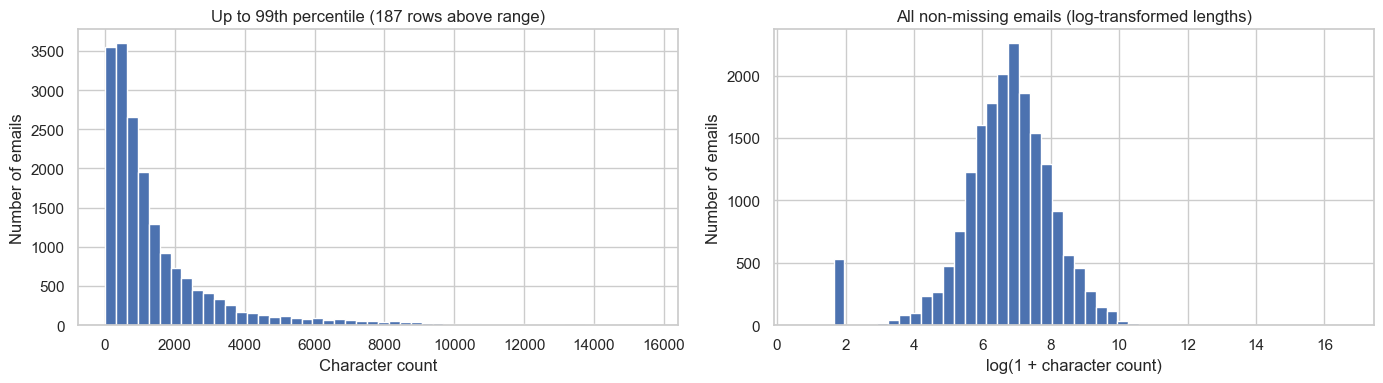

In [9]:
# Show lengths and the full distribution, including extreme values.
if not char_counts.empty:
    char_limit = char_counts.quantile(.99)
    above_limit = char_counts.gt(char_limit).sum()
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].hist(char_counts[char_counts <= char_limit], bins=50, edgecolor='white')
    axes[0].set(
        title=f'Up to 99th percentile ({above_limit:,} rows above range)',
        xlabel='Character count', ylabel='Number of emails',
    )
    axes[1].hist(np.log1p(char_counts), bins=50, edgecolor='white')
    axes[1].set(
        title='All non-missing emails (log-transformed lengths)',
        xlabel='log(1 + character count)', ylabel='Number of emails',
    )
    plt.tight_layout()
    plt.show()


### Scatter plot and candidate cutoff


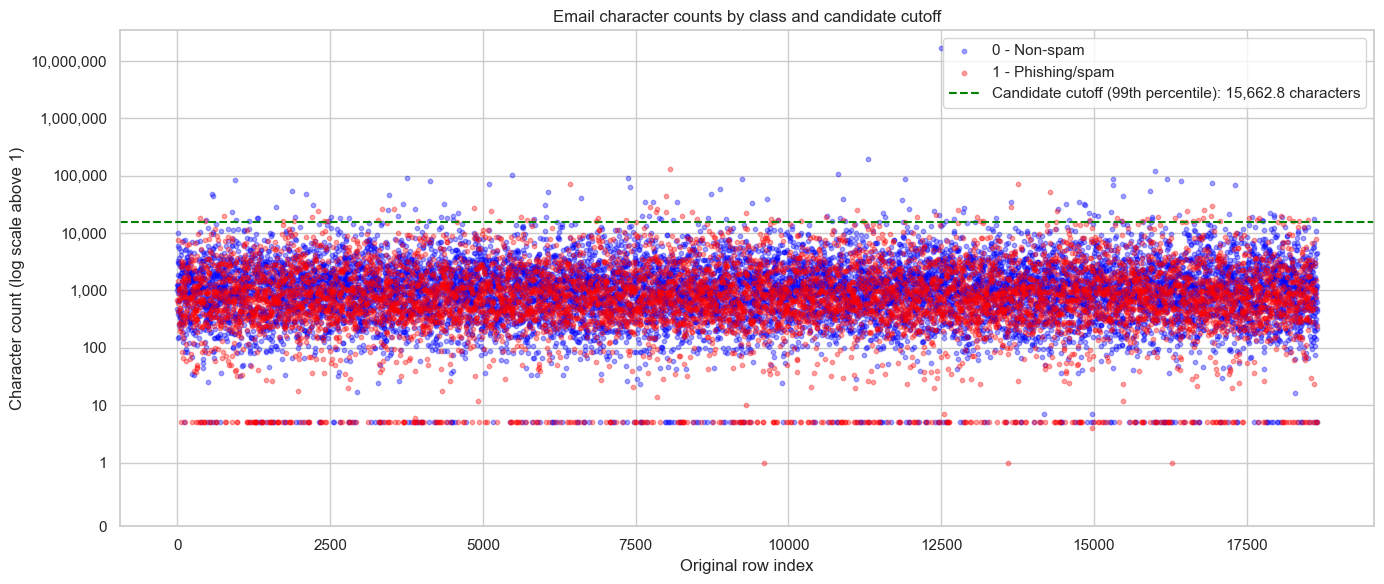

Emails above cutoff: 187


In [10]:
# Use the 99th percentile of character counts as the candidate cutoff.
char_review_threshold = char_counts.quantile(.99)

fig, ax = plt.subplots(figsize=(14, 6))
email_labels = df_phishing_email.loc[char_counts.index, 'label']
for value, color, name in [(0, 'blue', '0 - Non-spam'), (1, 'red', '1 - Phishing/spam')]:
    class_counts = char_counts[email_labels.eq(value)]
    ax.scatter(class_counts.index, class_counts, color=color, label=name, s=10, alpha=.35, rasterized=True)

ax.axhline(
    char_review_threshold, color='green', linestyle='--',
    label=f'Candidate cutoff (99th percentile): {char_review_threshold:,.1f} characters',
)
ax.set_yscale('symlog', linthresh=1)
ax.set_ylim(0, max(char_counts.max(), 1) * 2)
ax.yaxis.set_major_formatter('{x:,.0f}')
ax.set(
    title='Email character counts by class and candidate cutoff',
    xlabel='Original row index', ylabel='Character count (log scale above 1)',
)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

print(f'Emails above cutoff: {char_counts.gt(char_review_threshold).sum():,}')


#### Since there are good number of emails above the 99th percentile and many of those are spam labeled , so instead of deleting the rows above 99th percentile we will truncate the mail to the 99th percentile thereby keeping the most important information but reducing the text to process. It could be that some mails have attachments 

In [11]:
df_combined = df_phishing_email.copy()
print(f'Loaded {len(df_combined):,} original rows from {DATA_PATH}')
display(df_combined['label'].value_counts(dropna=False).rename('raw_rows').to_frame())

Loaded 18,650 original rows from dataset/phishing_email_1_dataset/Phishing_Email.csv


,raw_rows
label,
0,11322
1,7328


## 3. Data preprocessing methods

Clean each email once into `word_text`, retain its original `text`, and reuse these
DataFrame columns to compute the nine count features. The prepared corpus feeds
the grouped split, training-data analysis, and TF-IDF augmentation.


### Preprocessing logic - flow

`df_combined` → `prepare_count_dataset()` → prepared `corpus` → grouped split → TF-IDF + nine counts

1. **Validate input:** `prepare_email_corpus()` copies the DataFrame, checks the text and label columns, accepts numeric 0/1 labels, and excludes missing labels.
2. **Clean emails once:** Preserve original emails in `text`; apply `clean_email_text()` once to create `word_text`, removing HTML tags, script/style contents, URLs, addresses, numbers, and other punctuation while retaining words, apostrophes, and stopwords.
3. **Filter and deduplicate:** Remove blank or unusable emails, hash whitespace-normalized original text into `content_hash`, exclude conflicting labels, and keep one row per exact duplicate group.
4. **Create split groups:** Build `group_id` from normalized words using the protected-stopword policy; retain the full word sequence when fewer than eight filtered words remain, and require both label classes after cleaning.
5. **Extract word features:** `extract_count_features(corpus)` reuses `word_text`, removes NLTK stopwords while protecting category words and negations, and counts retained words plus urgency, account, threat, financial, and official terms; phrase matches preserve original adjacency.
6. **Extract structural features:** Count HTTP/HTTPS occurrences in raw `text` and sentences in visible text with URLs/addresses removed and punctuation preserved; these three counts plus the six word features make nine features.
7. **Assemble the corpus:** `prepare_count_dataset()` joins the nine integer features and stopword-filtered `clean_text` to the prepared rows, preserving alignment and retaining `text`, `word_text`, labels, and group identifiers.
8. **Split and build model inputs:** `split_email_corpus()` creates an approximately 80/20 grouped train/holdout split and three training CV folds; TF-IDF uses `word_text` with the same stopword policy, fits on training data, and appends the nine counts. Keeping the TF-IDF limited to training set so as it doesnt learnfrom the holdout set.

During model cross-validation, the pipeline refits TF-IDF within each training fold; labels and group identifiers are excluded from predictors.


In [12]:
def truncate_email_text(frame, text_column="text_combined", percentile=.99):
    """Cap text using char_count's percentile and return a copy without char_count."""
    if not 0 < percentile <= 1:
        raise ValueError("percentile must be greater than 0 and at most 1.")

    cutoff = frame["char_count"].quantile(percentile)
    if pd.isna(cutoff):
        raise ValueError("char_count must contain non-missing lengths.")

    truncated = frame.copy()
    above_cutoff = truncated["char_count"].gt(cutoff).fillna(False)
    truncated.loc[above_cutoff, text_column] = (
        truncated.loc[above_cutoff, text_column]
        .astype("string")
        .str.slice(stop=int(np.ceil(cutoff)))
    )
    return truncated.drop(columns="char_count")


In [13]:
"""Nine count features and a TF-IDF comparison for Phishing_email dataset.

We are using a numeric label 0=legitimate, 1=phishing.  

"""

# Keep alphabetic words and internal apostrophes; digits and underscores are excluded.
TOKEN_PATTERN = r"(?u)\b[^\W\d_]+(?:'[^\W\d_]+)*\b"

WORD_RE = re.compile(TOKEN_PATTERN)

URL_RE = re.compile(r"\b(?:https?://|www\.)[^\s<>\"']+", re.I)

EMAIL_RE = re.compile(r"\b[^\s<>@]+@[^\s<>@]+\.[^\s<>@]+\b")

# Five fixed keyword categories complement the four structural/length features.
# Terms may overlap: a longer phrase and its component term can both contribute counts.
TERM_CATEGORIES = {
    "urgency": {
        "urgent", "immediate", "immediately", "action required", "attention required", "respond now",
        "expires", "expiring", "deadline", "limited time", "act now", "urgent action", "click",
        "here", "now", "free", "offer", "buy", "purchase", "donate", "subscribe", "register",
        "sign up", "get started", "learn more",
    },
    "account": {
        "verify", "verification", "authenticate", "confirm", "validate", "reactivate",
        "suspended", "blocked", "restricted", "limited", "unlock", "secure", "security",
        "access", "password", "login", "account", "username", "credential",
    },
    "threat": {
        "terminate", "deactivate", "delete", "removal", "suspend", "restriction",
        "warning", "risk", "compromised", "suspicious", "unauthorized", "disabled",
        "cancelled", "violation", "breach", "illegal",
    },
    "financial": {
        "claim", "prize", "winner", "won", "reward", "bonus", "payment", "refund",
        "deposit", "transfer", "transaction", "million", "inheritance", "lottery",
        "cash", "credit", "bank", "money", "fund", "balance",
    },
    "official": {
        "official", "authorized", "authentication", "notification", "notice", "alert",
        "department", "administration", "support", "service", "helpdesk",
    },
}

# HTMLParser calls the handlers below when feed() reads the HTML.


class VisibleText(HTMLParser):
    """Collect text outside script/style elements using HTMLParser callbacks.

    Attributes
    ----------
    parts : list[str]
        Accepted text fragments in encounter order; joined by visible_email_text.
    suppressed : int
        Number of currently open script/style elements used to suppress their data.

    Notes
    -----
    This is a text extractor, not a browser renderer: it does not interpret CSS,
    recover MIME attachments, or read text from images.
    """
    def __init__(self):
        """Initialize text fragments and the script/style suppression counter."""
        super().__init__(convert_charrefs=True)
        self.parts = []
        self.suppressed = 0

    def handle_starttag(self, tag, attrs):
        """Start suppressing text when a script or style element opens."""
        if tag in {"script", "style"}:
            self.suppressed += 1

    def handle_endtag(self, tag):
        """End suppression when a script or style element closes."""
        if tag in {"script", "style"} and self.suppressed:
            self.suppressed -= 1

    def handle_data(self, data):
        """Collect text only when the suppression counter is zero."""
        if not self.suppressed:
            self.parts.append(data)


def visible_email_text(value):
    """Extract visible text while preserving case and sentence punctuation.

    Parameters
    ----------
    value : scalar object
        Raw email value, usually str; a missing scalar returns an empty string.

    Returns
    -------
    str
        Text without parsed HTML tags or script/style contents, with entities decoded
        and curly apostrophes normalized. Case and punctuation are otherwise retained.
    """
    if pd.isna(value):
        return ""
    text = str(value)
    if re.search(r"</?[A-Za-z][^>]*>", text):
        parser = VisibleText()
        parser.feed(text)
        text = " ".join(parser.parts)
    return html.unescape(text).replace("\u2019", "'")


def clean_email_text(value):
    """Basic word-only view; keep the original text separately for URL features.

    Does not decode MIME/base64/quoted-printable or recover previously removed URLs.
    Preserves apostrophes/negation and word order; removes tags, URLs and addresses.

    Parameters
    ----------
    value : scalar object
        Raw email text or a missing scalar, passed through visible_email_text first.

    Returns
    -------
    str
        Case-folded, space-separated alphabetic/apostrophe tokens in original order.
        Stopwords are still present: the caller applies the shared stopword policy.
    """
    text = visible_email_text(value).casefold()
    text = URL_RE.sub(" ", text)
    text = EMAIL_RE.sub(" ", text)
    return " ".join(WORD_RE.findall(text))


def get_protected_feature_words():
    """Collect every token from the five keyword categories among the nine features.

    Phrase components are protected , such as 'up' in 'sign up'. URL and
    sentence counts are extracted from original text, before stopword removal.

    Parameters
    ----------
    None
        Reads the shared TERM_CATEGORIES dictionary and text-normalization rules.

    Returns
    -------
    set[str]
        Unique normalized tokens from every category term, including phrase components.
        This is a set of words to retain, not an additional stopword source.
    """
    return {
        word
        for category in TERM_CATEGORIES.values()
        for term in category
        for word in clean_email_text(term).split()
    }


def get_effective_nltk_stopwords(stop_words=None):
    """Return NLTK English stopwords minus feature words and protected negations.

    Only NLTK stopwords or a subset are accepted; extra words are rejected, and negations are preserved.

    Parameters
    ----------
    stop_words : iterable[str] | None, default None
        None uses the full NLTK English list before applying feature-word and negation exclusions.

    Returns
    -------
    set[str]
        NLTK stopwords excluding protected feature words and negations.

    Raises
    ------
    ValueError
        If a supplied word is not in the NLTK English stopword set.
    LookupError or  the NLTK stopwords corpus has not been installed.
    """
    nltk_words = set(stopwords.words('english'))
    if stop_words is None:
        candidate_words = nltk_words
    else:
        candidate_words = {word.casefold() for word in stop_words}
        unsupported = candidate_words - nltk_words
        if unsupported:
            raise ValueError(f'Only NLTK English stopwords are allowed: {sorted(unsupported)}')

    # Preserve category words, including every component of a phrase.
    protected = get_protected_feature_words()
    # Protect common negation words so key sentiment signals are preserved.
    protected.update({'no', 'not', 'nor', 'never', 'cannot', "don't", "doesn't", "isn't", "won't"})
    protected.update(word for word in nltk_words if word.endswith("n't"))
    return candidate_words - protected

# One shared, corpus-supplied list; no custom email/header/HTML stopwords.
NLTK_STOP_WORDS = set(stopwords.words('english'))
PROTECTED_FEATURE_WORDS = get_protected_feature_words()
EFFECTIVE_STOP_WORDS = get_effective_nltk_stopwords()

assert EFFECTIVE_STOP_WORDS <= NLTK_STOP_WORDS
assert EFFECTIVE_STOP_WORDS.isdisjoint(PROTECTED_FEATURE_WORDS)


In [14]:
COUNT_FEATURE_COLUMNS = [
    "http_url_count", "https_url_count", "sentence_count", "total_word_count",
    "urgency_terms_count", "account_terms_count", "threat_terms_count",
    "financial_terms_count", "official_terms_count",
]

# Matching hashes identify equal normalized text, not arbitrary near-duplicates.


def _hash(value):
    """Create a deterministic identifier for a supplied text representation.

    Parameters
    ----------
    value : str
        Text already normalized by the caller; encoded as UTF-8 before hashing.

    Returns
    -------
    str
        64-character SHA-256 hexadecimal digest. Equal input strings have equal hashes;
        hashing itself does not perform fuzzy matching or measure semantic similarity.
    """
    return hashlib.sha256(value.encode("utf-8")).hexdigest()

def prepare_email_corpus(frame, text_column="text_combined", label_column="label"):
    """Return cleaned, 99th-percentile-capped text without char_count or changes to the input.

    Deduplication: Remove exact duplicates, ignoring whitespace differences.
    Conflicts: Exclude identical text with conflicting labels.
    Grouping: Group normalized matches for splitting without deleting or relabeling them.

    Args:
        frame (pandas.DataFrame): Source emails and binary labels.
        text_column (str, default="text_combined"): Original email text column.
        label_column (str, default="label"): Numeric 0/1 label column; exclude missing labels.

    Returns:
        pandas.DataFrame: Unique emails with capped text_column and word_text, original text in text, int64 labels, content_hash, group_id, and a reset index.

    Raises:
        ValueError: Missing columns, invalid labels, or fewer than two classes after cleaning.
    """

    if not {text_column, label_column}.issubset(frame.columns):
        raise ValueError(f"Expected columns {text_column!r} and {label_column!r}.")

    data = frame.copy().reset_index(drop=True)

    data["text"] = data[text_column].fillna("").astype(str)

    target = pd.to_numeric(data[label_column], errors="raise")

    if not target.dropna().isin([0, 1]).all():
        raise ValueError("Labels must be 0 or 1; missing labels will be excluded.")

    data["label"] = target.astype("Int64")

    data = data[data["label"].notna()].copy()

    exact = data["text"].str.replace(r"\s+", " ", regex=True).str.strip()

    # Clean each email once; feature extraction reuses word_text.
    # Keep stopwords here to preserve positions for phrase matching.
    data["word_text"] = data["text"].map(clean_email_text)

    empty_mask = exact.str.casefold().isin(["", "empty"]) | data["word_text"].eq("")
    data = data[~empty_mask].copy()

    data["content_hash"] = exact.loc[data.index].map(_hash)

    counts = data.groupby("content_hash")["label"].nunique()
    consistent = data[~data["content_hash"].isin(counts.index[counts > 1])].copy()

    corpus = consistent.drop_duplicates("content_hash", keep="first").copy()

    grouping_stop_words = get_effective_nltk_stopwords()

    # The normalization creates grouping keys, not learned predictors or relabeled targets.
    def split_key(text):
        """Inner function split text, remove stopwords and then generate hash
        Parameters
        ----------
        text : str
            Normalized word_text; grouping_stop_words is inherited from the enclosing call.

        Returns
        -------
        str
            SHA-256 hash of the stopword-filtered sequence when at least eight tokens
            remain; otherwise hashes the full word sequence to keep short texts specific.
            Only identical resulting sequences are grouped; paraphrases may remain separate.
        """
        words = text.split()
        reduced = [w for w in words if w not in grouping_stop_words]
        # Keep short texts specific rather than group all generic short messages.
        return _hash(" ".join(reduced if len(reduced) >= 8 else words))

    # Keep identical normalized group keys in the same split.
    corpus["group_id"] = corpus["word_text"].map(split_key)

    corpus["label"] = corpus["label"].astype("int64")
    corpus = corpus.reset_index(drop=True)

    if corpus["label"].nunique() != 2:
        raise ValueError("Both classes are required after cleaning.")

    # Count cleaned characters for truncation; the helper drops char_count afterward.
    corpus["char_count"] = corpus["word_text"].str.len()
    corpus = truncate_email_text(corpus, text_column="word_text")
    corpus[text_column] = corpus["word_text"]
    return corpus


In [15]:
# Split original prepared rows before learning any vocabulary, IDF, or scaler.


def split_email_corpus(corpus, holdout_folds=5, cv_folds=3, random_state=42):
    """Approx. 1/holdout_folds held out; groups cannot cross holdout/CV splits.

    Parameters
    ----------
    corpus : pandas.DataFrame
        Prepared rows containing text, label in {0, 1}, and group_id.
    holdout_folds : int, default 5
        Number of grouped folds for the outer split; the first fold becomes holdout.
        Group sizes make the resulting fraction approximate rather than exactly 20%.
    cv_folds : int, default 3
        Number of stratified grouped folds constructed only within training rows.
    random_state : int, default 42
        Seed for reproducible shuffled splits.

    Returns
    -------
    train : pandas.DataFrame
        Training data with its row index reset.
    test : pandas.DataFrame
        Test data with its row index reset.
    splits : list of tuples
        Each tuple contains (fit_positions, validation_positions) for one
        cross-validation split. Both are integer arrays of row positions
        in train, accessed using train.iloc.

    Raises
    ------
    ValueError
        If too few groups exist per class or a resulting partition lacks a class.
    """

    if corpus.groupby("label")["group_id"].nunique().min() < holdout_folds:
        raise ValueError("Too few distinct groups per class for the requested holdout split.")

    splitter = StratifiedGroupKFold(
        n_splits=holdout_folds, shuffle=True, random_state=random_state
    )

    train_idx, test_idx = next(splitter.split(corpus["text"], corpus["label"], corpus["group_id"]))

    train = corpus.iloc[train_idx].reset_index(drop=True)
    test = corpus.iloc[test_idx].reset_index(drop=True)

    if train["label"].nunique() != 2 or test["label"].nunique() != 2:
        raise ValueError("This grouped holdout lacks a class; reconsider the split configuration.")

    if train.groupby("label")["group_id"].nunique().min() < cv_folds:
        raise ValueError("Too few training groups per class for CV.")

    cv = StratifiedGroupKFold(n_splits=cv_folds, shuffle=True, random_state=random_state)
    splits = list(cv.split(train["text"], train["label"], train["group_id"]))

    for fit_idx, valid_idx in splits:
        if any(train.iloc[idx]["label"].nunique() != 2 for idx in (fit_idx, valid_idx)):
            raise ValueError("A grouped CV fold lacks a class; reconsider the split configuration.")

    return train, test, splits


In [16]:
def extract_count_features(corpus, stop_words=None, sentence_tokenizer=None):
    """Return (features, cleaned), preserving corpus.index and excluding labels.

    Args:
        corpus (pd.DataFrame): Original text and precleaned word_text
        stop_words (iterable[str] | None): NLTK English subset or full list if None; protect category words, phrase components, and negations.
        sentence_tokenizer (callable | None): Maps text to a sequence of sentences; defaults to nltk.sent_tokenize.

    Counting rules:
        Words: Count retained alphabetic/apostrophe tokens, excluding URLs, addresses, numbers, and punctuation.
        Terms: Count repeated and overlapping matches; phrases require original word adjacency.
        URLs: Count every raw HTTP/HTTPS occurrence, including those in HTML attributes.
        Sentences: Use visible text without URLs/addresses, before stopword filtering.

    Returns:
        features (pd.DataFrame): Shape (n_emails, 9), with int64 counts in COUNT_FEATURE_COLUMNS order.
        cleaned (pd.Series): Stopword-filtered strings named clean_text.
    """

    if stop_words is None:
        from nltk.corpus import stopwords
        stop_words = set(stopwords.words("english"))

    if sentence_tokenizer is None:
        from nltk.tokenize import sent_tokenize
        sentence_tokenizer = sent_tokenize

    # Check tokenizer availability once.
    sentence_tokenizer("Tokenizer check.")

    # Normalize terms like the stored email words.
    terms = {name: [tuple(clean_email_text(t).split()) for t in sorted(values)]
             for name, values in TERM_CATEGORIES.items()}

    # Protect all phrase components.
    protected = {w for category in terms.values() for term in category for w in term}

    # Preserve category words and negations.
    effective_stop_words = get_effective_nltk_stopwords(stop_words)
    assert effective_stop_words.isdisjoint(protected)

    max_n = max(len(term) for category in terms.values() for term in category)

    raw = corpus["text"]
    records, cleaned = [], []

    for text, word_text in zip(raw, corpus["word_text"]):
        # Keep positions before stopword removal.
        words = word_text.split()
        kept = [(i, w) for i, w in enumerate(words) if w not in effective_stop_words]
        filtered = [w for _, w in kept]
        cleaned.append(" ".join(filtered))

        occurrences = Counter((w,) for w in filtered)

        # Require original adjacency for phrase matches.
        for n in range(2, max_n + 1):
            for i in range(len(kept) - n + 1):
                window = kept[i:i+n]
                if window[-1][0] - window[0][0] == n - 1:
                    occurrences[tuple(w for _, w in window)] += 1

        # Keep punctuation for sentence boundaries.
        visible = EMAIL_RE.sub(" ", URL_RE.sub(" ", visible_email_text(text))).strip()

        record = {
            "http_url_count": len(re.findall(r"\bhttp://[^\s<>\"']+", text, re.I)),
            "https_url_count": len(re.findall(r"\bhttps://[^\s<>\"']+", text, re.I)),
            "sentence_count": len(sentence_tokenizer(visible)) if visible else 0,
            "total_word_count": len(filtered),
        }

        record.update({f"{name}_terms_count": sum(occurrences[t] for t in category)
                       for name, category in terms.items()})
        records.append(record)

    features = pd.DataFrame(records, columns=COUNT_FEATURE_COLUMNS, index=raw.index).astype("int64")

    return features, pd.Series(cleaned, index=raw.index, name="clean_text")


def prepare_count_dataset(frame, stop_words=None, sentence_tokenizer=None):
    """Return the prepared corpus with raw text, nine features, and cleaned text.

    Input columns: text_combined and label. Uses no learned word vocabulary or
    label-based feature selection

    Parameters
    ----------
    frame : pandas.DataFrame
        Original email data with text_combined and numeric label columns.
    stop_words : iterable[str] | None, default None
        Optional NLTK subset passed to extract_count_features.
    sentence_tokenizer : callable(str) -> sequence[str] | None, default None
        Optional sentence tokenizer passed to extract_count_features.

    Returns
    -------
    pandas.DataFrame
        Prepared corpus containing retained text/metadata, int64 label, all nine
        int64 count columns, and clean_text. Original text and word_text remain
        available for the classifier.
    """
    corpus = prepare_email_corpus(frame)
    features, cleaned = extract_count_features(corpus, stop_words, sentence_tokenizer)
    # Re-running on a frame containing feature columns replaces them, not duplicates.
    corpus = corpus.drop(columns=COUNT_FEATURE_COLUMNS + ["clean_text"], errors="ignore")
    return pd.concat([corpus, features, cleaned], axis=1)


In [17]:
# Build the corpus once, then create independent training/holdout partitions.
# Targets and group identifiers are kept alongside the rows but excluded from predictors.

corpus = prepare_count_dataset(df_combined)

In [18]:
print(corpus.info())
print(corpus.head(10))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17511 entries, 0 to 17510
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   text_combined          17511 non-null  object
 1   label                  17511 non-null  int64 
 2   text                   17511 non-null  object
 3   word_text              17511 non-null  object
 4   content_hash           17511 non-null  object
 5   group_id               17511 non-null  object
 6   http_url_count         17511 non-null  int64 
 7   https_url_count        17511 non-null  int64 
 8   sentence_count         17511 non-null  int64 
 9   total_word_count       17511 non-null  int64 
 10  urgency_terms_count    17511 non-null  int64 
 11  account_terms_count    17511 non-null  int64 
 12  threat_terms_count     17511 non-null  int64 
 13  financial_terms_count  17511 non-null  int64 
 14  official_terms_count   17511 non-null  int64 
 15  clean_text         

In [19]:
display(corpus.describe())

# Summarize cleaned, truncated email lengths, including spaces; preserve missing text.
corpus_char_counts = corpus['word_text'].astype('string').str.len()
print(f"Missing text: {corpus_char_counts.isna().sum():,} rows")
print(f"Empty text: {corpus_char_counts.eq(0).sum():,} rows")
display(corpus_char_counts.dropna().astype('int64').describe(percentiles=[.25, .5, .75, .9, .95, .99, .999]).to_frame('char_count'))


,label,http_url_count,https_url_count,sentence_count,total_word_count,urgency_terms_count,account_terms_count,threat_terms_count,financial_terms_count,official_terms_count
count,17511.000000,17511.000000,17511.000000,17511.000000,17511.000000,17511.000000,17511.000000,17511.000000,17511.000000,17511.000000
mean,0.373194,0.679744,0.055908,33.505282,157.561932,1.634687,0.472674,0.193079,0.999201,0.443036
std,0.483667,23.794861,0.300225,1687.781894,223.525685,3.357187,1.586830,0.824877,3.613842,1.280681
min,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,5.000000,40.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,10.000000,81.000000,1.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,0.000000,0.000000,19.000000,175.000000,2.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,3131.000000,6.000000,223247.000000,3113.000000,116.000000,36.000000,25.000000,80.000000,30.000000


Missing text: 0 rows
Empty text: 0 rows


,char_count
count,17511.000000
mean,1458.131003
std,2095.040932
min,3.000000
25%,351.000000
50%,732.000000
75%,1611.000000
90%,3367.000000
95%,5486.000000
99%,12994.700000


In [20]:
print(corpus.columns)

Index(['text_combined', 'label', 'text', 'word_text', 'content_hash',
       'group_id', 'http_url_count', 'https_url_count', 'sentence_count',
       'total_word_count', 'urgency_terms_count', 'account_terms_count',
       'threat_terms_count', 'financial_terms_count', 'official_terms_count',
       'clean_text'],
      dtype='object')


**Split and build model inputs:** `split_email_corpus()` creates an approximately 80/20 grouped train/holdout split and three training CV folds; TF-IDF uses `word_text` with the same stopword policy, fits on training data, and appends the nine counts. Keeping the TF-IDF limited to training set so as it doesnt learnfrom the holdout set.

In [21]:
train_df, holdout_df, cv_splits = split_email_corpus(
    corpus,
    holdout_folds=5,  # Approximately 80% training and 20% holdout.
    cv_folds=3,
    random_state=RANDOM_STATE,
)
test_df = holdout_df  # Both names refer to the same held-out partition.

# Metadata and targets stay outside the feature matrices.
y_train = train_df[TARGET_COLUMN].to_numpy(dtype=np.int64)
y_test = test_df[TARGET_COLUMN].to_numpy(dtype=np.int64)
y_holdout = y_test
groups_train = train_df['group_id'].to_numpy()
groups_test = test_df['group_id'].to_numpy()
X_train_text = train_df[TEXT_COLUMN].copy()
X_holdout_text = test_df[TEXT_COLUMN].copy()

assert set(groups_train).isdisjoint(groups_test)
assert set(train_df['content_hash']).isdisjoint(test_df['content_hash'])
for fit_idx, valid_idx in cv_splits:
    assert set(groups_train[fit_idx]).isdisjoint(groups_train[valid_idx])

split_summary = pd.DataFrame({
    'rows': [len(train_df), len(test_df)],
    'share_of_clean_corpus': [len(train_df) / len(corpus), len(test_df) / len(corpus)],
    'safe': [(y_train == 0).sum(), (y_test == 0).sum()],
    'phishing': [(y_train == 1).sum(), (y_test == 1).sum()],
}, index=['Training', 'Holdout / test'])
display(split_summary)


,rows,share_of_clean_corpus,safe,phishing
Training,14109,0.805722,8817,5292
Holdout / test,3402,0.194278,2159,1243


## 4. Create the TF-IDF data

Use the training and holdout rows created by the grouped split in Section 3.

- **Input:** Read the prepared `word_text` column; email cleaning is already complete.
- **Stopwords:** Apply `EFFECTIVE_STOP_WORDS`, the NLTK English list with category words, phrase components, and negations protected.
- **Training:** Use `fit_transform()` to learn the vocabulary and IDF weights from training emails and create `X_train_tfidf`.
- **Holdout:** Use the same fitted vectorizer's `transform()` to create `X_test_tfidf`, preserving the training vocabulary and IDF weights.
- **Output:** Store sparse `float32` matrices with identical feature columns and rows aligned with `y_train` and `y_test`; `MAX_FEATURES_TFIDF` sets the vocabulary cap.

Sections 5–6 analyze a full copy of `corpus` with the nine count features transformed by `log1p`. Section 7 appends those raw counts to the TF-IDF matrices to create `X_train_augmented` and `X_test_augmented`; Section 8 checks their shapes, feature order, and label alignment.

For model tuning in Section 13, the shared preprocessing defined in Section 9 receives the prepared DataFrames and refits TF-IDF within each CV training fold. Validation and holdout rows use the corresponding fitted transformation; the matrices created here are kept for inspection, export, or direct training with the fixed holdout.

Reference: [scikit-learn TfidfVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html).


In [22]:
# Learn the exportable TF-IDF vocabulary and IDF only from training emails.
# The classification CV pipeline will independently refit this preprocessing within each fold.

tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    token_pattern=TOKEN_PATTERN,
    stop_words=sorted(EFFECTIVE_STOP_WORDS),  # NLTK only, with feature words excluded.
    ngram_range=NGRAM_RANGE,
    max_features=MAX_FEATURES_TFIDF,
    min_df=MIN_DF,
    dtype=np.float32,
)

# Fit only on training text.
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_text).tocsr()
# Transform holdout text using the training vocabulary.
X_test_tfidf = tfidf_vectorizer.transform(X_holdout_text).tocsr()
X_holdout_tfidf = X_test_tfidf
tfidf_terms = tfidf_vectorizer.get_feature_names_out()
tfidf_feature_names = np.array(['tfidf__' + term for term in tfidf_terms])

y_train_tfidf, y_holdout_tfidf = y_train, y_test  # Familiar Week 4 aliases.

# Sparse DataFrames provide named TF-IDF columns without densifying the data.
tfidf_train_df = pd.DataFrame.sparse.from_spmatrix(X_train_tfidf, columns=tfidf_terms)
tfidf_test_df = pd.DataFrame.sparse.from_spmatrix(X_test_tfidf, columns=tfidf_terms)

print(f'TF-IDF features after NLTK stopword filtering: {len(tfidf_terms):,}')
print(f'Training TF-IDF: {X_train_tfidf.shape}; holdout TF-IDF: {X_test_tfidf.shape}')

# Check every unigram and bigram component: no removable stopword may remain.
tfidf_vocabulary_words = {word for term in tfidf_terms for word in term.split()}
assert EFFECTIVE_STOP_WORDS.isdisjoint(tfidf_vocabulary_words)
assert EFFECTIVE_STOP_WORDS.isdisjoint(PROTECTED_FEATURE_WORDS)
print('Verified: TF-IDF contains no effective stopwords; protected feature words are not filtered.')


TF-IDF features after NLTK stopword filtering: 5,000
Training TF-IDF: (14109, 5000); holdout TF-IDF: (3402, 5000)
Verified: TF-IDF contains no effective stopwords; protected feature words are not filtered.


## 5. Univariate and Bivariate analysis of the nine engineered features

Create `corpus_eda = corpus.copy()` and apply `np.log1p` once to the nine
`COUNT_FEATURE_COLUMNS`. Text, labels, metadata, and the original `corpus` stay unchanged.

Sections 5–6 use this copy of the full corpus, including training and holdout rows

In [23]:
# Transform only the nine count columns in a separate copy of the full corpus.
corpus_eda = corpus.copy()
corpus_eda[COUNT_FEATURE_COLUMNS] = np.log1p(corpus_eda[COUNT_FEATURE_COLUMNS])


### Analysis methods

The methods accept `corpus_eda`, select `COUNT_FEATURE_COLUMNS`, and group by `label`.
Histograms, correlations, violin/box plots, and KDE use all corpus rows.
Only the pairplot uses a reproducible, balanced sample of up to 1,000 rows as its taking a lot of time to generate.
Axes identify `log1p(count)` values; labels, text, and metadata are excluded from predictor axes.

In [24]:
def perform_univariate_analysis(df, kde=True):
    """Plot the nine log1p count distributions by label; optionally include KDE."""
    features = COUNT_FEATURE_COLUMNS
    n_cols = 3
    n_rows = (len(features) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4*n_rows), squeeze=False)
    fig.suptitle('Univariate Analysis: log1p Counts', fontsize=10, y=1.02)
    axes = axes.flatten()

    for ax, feature in zip(axes, features):
        sns.histplot(data=df, x=feature, hue='label', multiple='stack',
                     bins=35, kde=kde, ax=ax)
        ax.set(title=f'Distribution of {feature}', xlabel=f'log1p({feature})', ylabel='Emails')

    for ax in axes[len(features):]:
        fig.delaxes(ax)
    plt.tight_layout()
    plt.show()


In [25]:
def perform_bivariate_analysis(df, include_pairplot=True, include_violin=True):
    """Plot nine log1p counts: correlations, balanced pairplot, and distributions by label."""
    features = COUNT_FEATURE_COLUMNS
    plot_labels = {feature: f'log1p({feature})' for feature in features}

    # Correlate only the transformed count features, excluding labels and metadata.
    correlation_matrix = df[features].corr().rename(index=plot_labels, columns=plot_labels)
    plt.figure(figsize=(12, 8))
    sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
                fmt='.2f', square=True, vmin=-1, vmax=1)
    plt.title('Correlation Matrix of log1p Counts')
    plt.tight_layout()
    plt.show()

    if include_pairplot:
        pairplot_df = create_balanced_sample(
            df[features + ['label']], sample_size=1000, random_state=RANDOM_STATE,
        ).rename(columns=plot_labels)
        print(f'Pairplot sample: {len(pairplot_df):,} corpus rows, balanced by class.')
        pair_grid = sns.pairplot(
            pairplot_df, vars=list(plot_labels.values()), hue='label', diag_kind='kde',
            height=1.8, plot_kws={'alpha': 0.35, 's': 10},
            diag_kws={'cut': 0, 'warn_singular': False},
        )
        for ax in pair_grid.axes.flat:
            ax.set_xlabel(ax.get_xlabel(), fontsize=8)
            ax.set_ylabel(ax.get_ylabel(), fontsize=8)
            ax.tick_params(labelsize=8)
        plt.show()

    n_cols = 3
    n_rows = (len(features) + n_cols - 1) // n_cols
    if include_violin:
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4*n_rows), squeeze=False)
        fig.suptitle('Violin Plots: log1p Counts by Label', fontsize=10, y=1.02)
        for ax, feature in zip(axes.flat, features):
            sns.violinplot(data=df, x='label', y=feature, cut=0, ax=ax)
            ax.set(xlabel='Label (0 = Safe, 1 = Phishing)', ylabel=plot_labels[feature],
                   title=f'{feature} by Label')
        for ax in axes.flat[len(features):]:
            fig.delaxes(ax)
        plt.tight_layout()
        plt.show()

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4*n_rows), squeeze=False)
    fig.suptitle('Box Plots: log1p Counts by Label', fontsize=10, y=1.02)
    for ax, feature in zip(axes.flat, features):
        sns.boxplot(data=df, x='label', y=feature, ax=ax)
        ax.set(xlabel='Label (0 = Safe, 1 = Phishing)', ylabel=plot_labels[feature],
               title=f'{feature} by Label')
    for ax in axes.flat[len(features):]:
        fig.delaxes(ax)
    plt.tight_layout()
    plt.show()


In [26]:
def perform_kde_analysis(df):
    """Plot smoothed densities of the nine log1p counts by label, using all supplied rows."""
    features = COUNT_FEATURE_COLUMNS
    n_cols = 3
    n_rows = (len(features) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4*n_rows), squeeze=False)
    fig.suptitle('KDE Plots: log1p Counts by Label', fontsize=10, y=1.02)

    for ax, feature in zip(axes.flat, features):
        sns.kdeplot(data=df, x=feature, hue='label', cut=0, warn_singular=False, ax=ax)
        ax.set(title=f'KDE of {feature}', xlabel=f'log1p({feature})')

    for ax in axes.flat[len(features):]:
        fig.delaxes(ax)
    plt.tight_layout()
    plt.show()


In [27]:
def analyze_phishing_email_Univariate_data(df):
    """Display histograms and KDE for the corpus copy's nine log1p counts by label."""
    print('Performing Univariate Analysis...')
    perform_univariate_analysis(df)


def analyze_phishing_email_Bivariate_data(df, include_kde=False):
    """Display count relationships and class comparisons, with optional separate KDE plots."""
    print('Performing Bivariate Analysis...')
    perform_bivariate_analysis(df)
    if include_kde:
        print('Performing KDE Analysis...')
        perform_kde_analysis(df)


In [28]:
def create_balanced_sample(df, sample_size=1000, random_state=42):
    """Sample equally by label without replacement, capped by the smaller class; shuffle rows."""
    safe = df[df['label'] == 0]
    phishing = df[df['label'] == 1]
    per_class = min(sample_size // 2, len(safe), len(phishing))
    sample = pd.concat([
        safe.sample(n=per_class, random_state=random_state),
        phishing.sample(n=per_class, random_state=random_state),
    ])
    return sample.sample(frac=1, random_state=random_state).reset_index(drop=True)


In [29]:
# Summarize log1p counts; zero_percent is the percentage of emails without each feature.
count_feature_summary = corpus_eda[COUNT_FEATURE_COLUMNS].describe().T
count_feature_summary['zero_percent'] = corpus_eda[COUNT_FEATURE_COLUMNS].eq(0).mean() * 100
print(f'log1p-count summary: nine features, {len(corpus_eda):,} corpus emails.')
display(count_feature_summary.round(3))


log1p-count summary: nine features, 17,511 corpus emails.


,count,mean,std,min,25%,50%,75%,max,zero_percent
http_url_count,17511.0,0.219,0.476,0.000,0.000,0.000,0.000,8.049,78.665
https_url_count,17511.0,0.034,0.170,0.000,0.000,0.000,0.000,1.946,95.791
sentence_count,17511.0,2.451,0.986,0.693,1.792,2.398,2.996,12.316,0.000
total_word_count,17511.0,4.441,1.115,0.693,3.714,4.407,5.170,8.044,0.000
urgency_terms_count,17511.0,0.631,0.730,0.000,0.000,0.693,1.099,4.762,47.530
account_terms_count,17511.0,0.209,0.475,0.000,0.000,0.000,0.000,3.611,80.081
threat_terms_count,17511.0,0.100,0.313,0.000,0.000,0.000,0.000,3.258,89.133
financial_terms_count,17511.0,0.303,0.653,0.000,0.000,0.000,0.000,4.394,76.084
official_terms_count,17511.0,0.215,0.457,0.000,0.000,0.000,0.000,3.434,78.476


## 6. Univariate and Bivariate analysis using the 9 derived features

Used `corpus_eda`(copy of the corpus) directly to both analysis functions. Class means and medians,
histograms/KDE, correlations, violin plots, and boxplots all use the nine
log1p-transformed counts from the full corpus. Only the pairplot uses a balanced
sample of up to 1,000 rows. No additional log transform is applied here.

The mean and median table is in log1p units, not original count units.
Correlations describe transformed feature pairs, excluding `label` and metadata

#### Observation : Univariate analyis

All values use **`log1p(count) = ln(1 + count)`**; means are transformed values, not average raw counts. Ham = 0; spam = 1.

- **Sparse features:** Most URL and keyword counts cluster at zero and remain right-skewed. Log transformation compresses large values but preserves zeros.
- **Strongest class differences:** Urgency and financial terms are higher in spam (means **0.957 vs 0.437** and **0.497 vs 0.187**, respectively). Median urgency corresponds to about **2 occurrences in spam versus 0 in ham**; financial medians remain zero.
- **Other keywords:** Account terms are higher in spam, while threat and official terms show little separation. Their medians are zero in both classes.
- **Links and length:** HTTP/HTTPS means are higher in ham. Sentence and word counts overlap substantially; transformed word counts are approximately bell-shaped.
- **Interpretation:** Taller ham bars partly reflect its larger sample size, not necessarily higher within-class prevalence. Urgency and financial terms merit further analysis, but these plots do not establish predictive importance or statistical significance; feature combinations may be more informative.


#### Observation : Bivariate analyis

- **Email length:** Sentence and word counts have the strongest correlation (**0.83**), indicating overlapping length information, with substantial class overlap.
- **Length and keywords:** Word-count correlations with keyword counts range from **0.29–0.47**; longer emails offer more opportunities for keyword matches. Financial terms also correlate with account (**0.43**) and urgency (**0.41**) terms.
- **Class differences:** Urgency shows the clearest visual separation: spam's transformed median is about **1.10**, equivalent to **2 occurrences**, versus **0 for ham**. Financial and account terms are also more frequently nonzero in spam, although many spam messages contain none.
- **URL counts:** Most correlations with text features are near zero; HTTP and HTTPS correlate only **0.16**. HTTP counts are generally higher in ham, while HTTPS is sparse in both classes, so URL presence alone does not identify spam.
- **Limited separation:** Threat and official terms cluster at zero in both classes. No plotted feature pair clearly separates ham from spam completely.

**Interpretation limits:** Heatmap correlations are between features, not with the label. The pairplot's **1,000 class-balanced rows** do not represent actual class proportions. With many zeros, ordinary nonzero counts may appear as boxplot outliers without being data errors.

In [30]:
# Compare the mean and median of log1p counts by label across the full corpus.
count_class_comparison = (
    corpus_eda.groupby('label')[COUNT_FEATURE_COLUMNS]
    .agg(['mean', 'median']).T.rename(columns={0: 'Safe', 1: 'Phishing'})
)
print('log1p-count summaries by class (0 = Safe, 1 = Phishing):')
display(count_class_comparison.round(3))


log1p-count summaries by class (0 = Safe, 1 = Phishing):


label                          Safe  Phishing
http_url_count        mean    0.282     0.113
                      median  0.000     0.000
https_url_count       mean    0.046     0.015
                      median  0.000     0.000
sentence_count        mean    2.416     2.510
                      median  2.303     2.398
total_word_count      mean    4.472     4.389
                      median  4.477     4.290
urgency_terms_count   mean    0.437     0.957
                      median  0.000     1.099
account_terms_count   mean    0.164     0.283
                      median  0.000     0.000
threat_terms_count    mean    0.090     0.117
                      median  0.000     0.000
financial_terms_count mean    0.187     0.497
                      median  0.000     0.000
official_terms_count  mean    0.212     0.220
                      median  0.000     0.000

Performing Univariate Analysis...


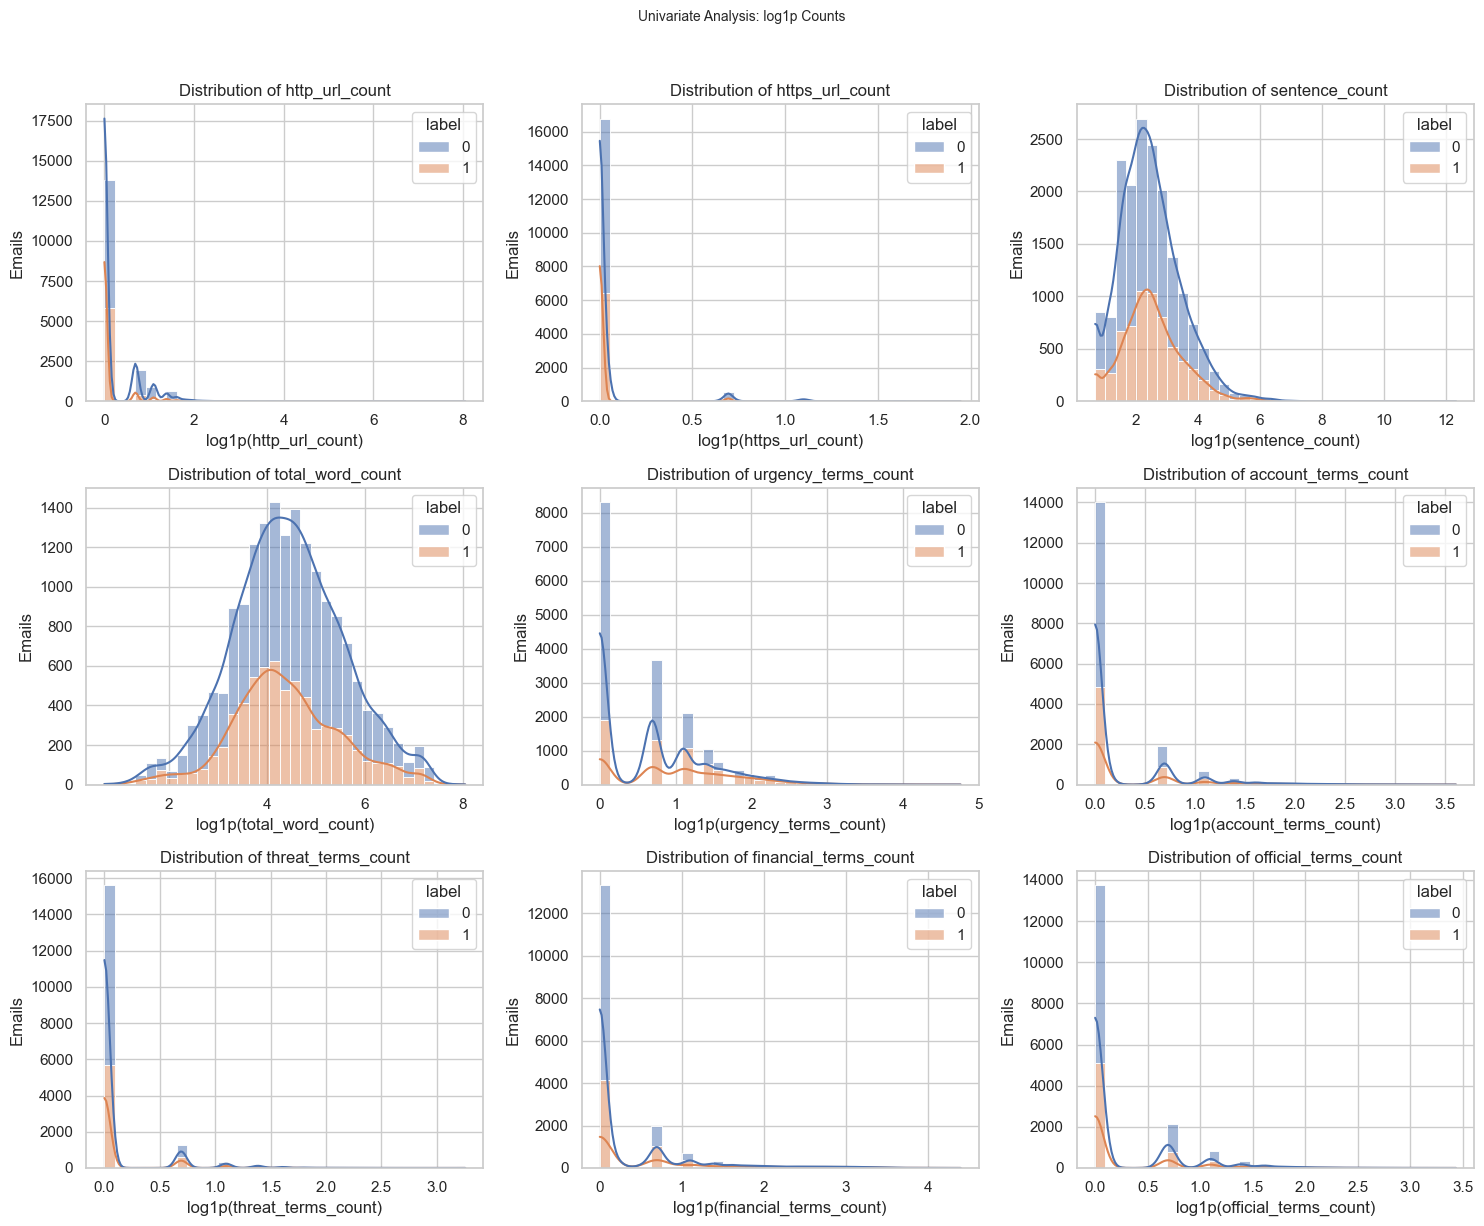

Performing Bivariate Analysis...


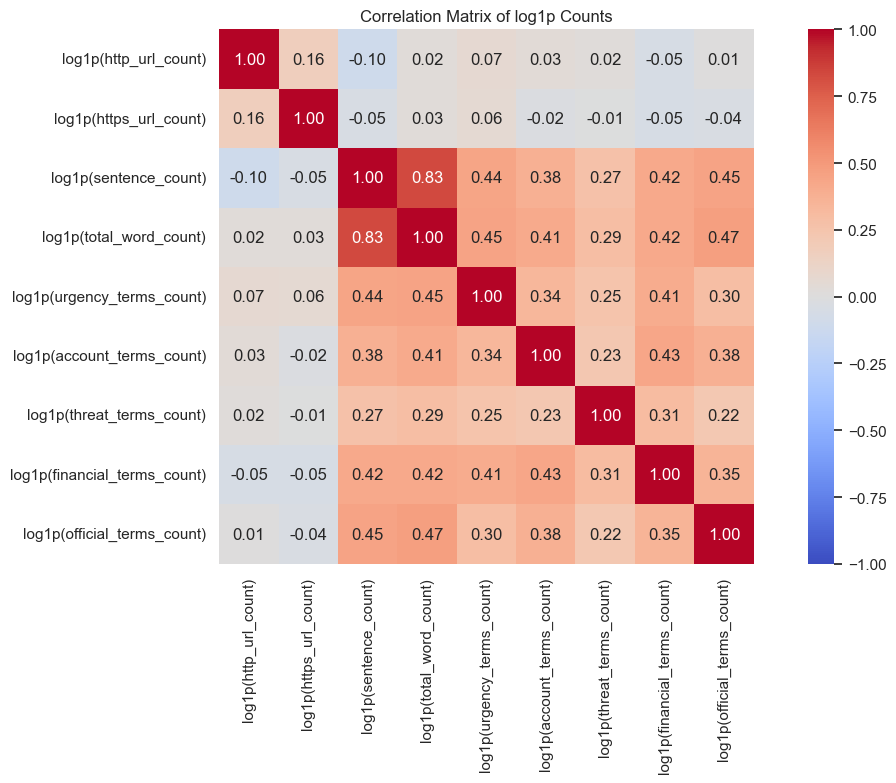

Pairplot sample: 1,000 corpus rows, balanced by class.


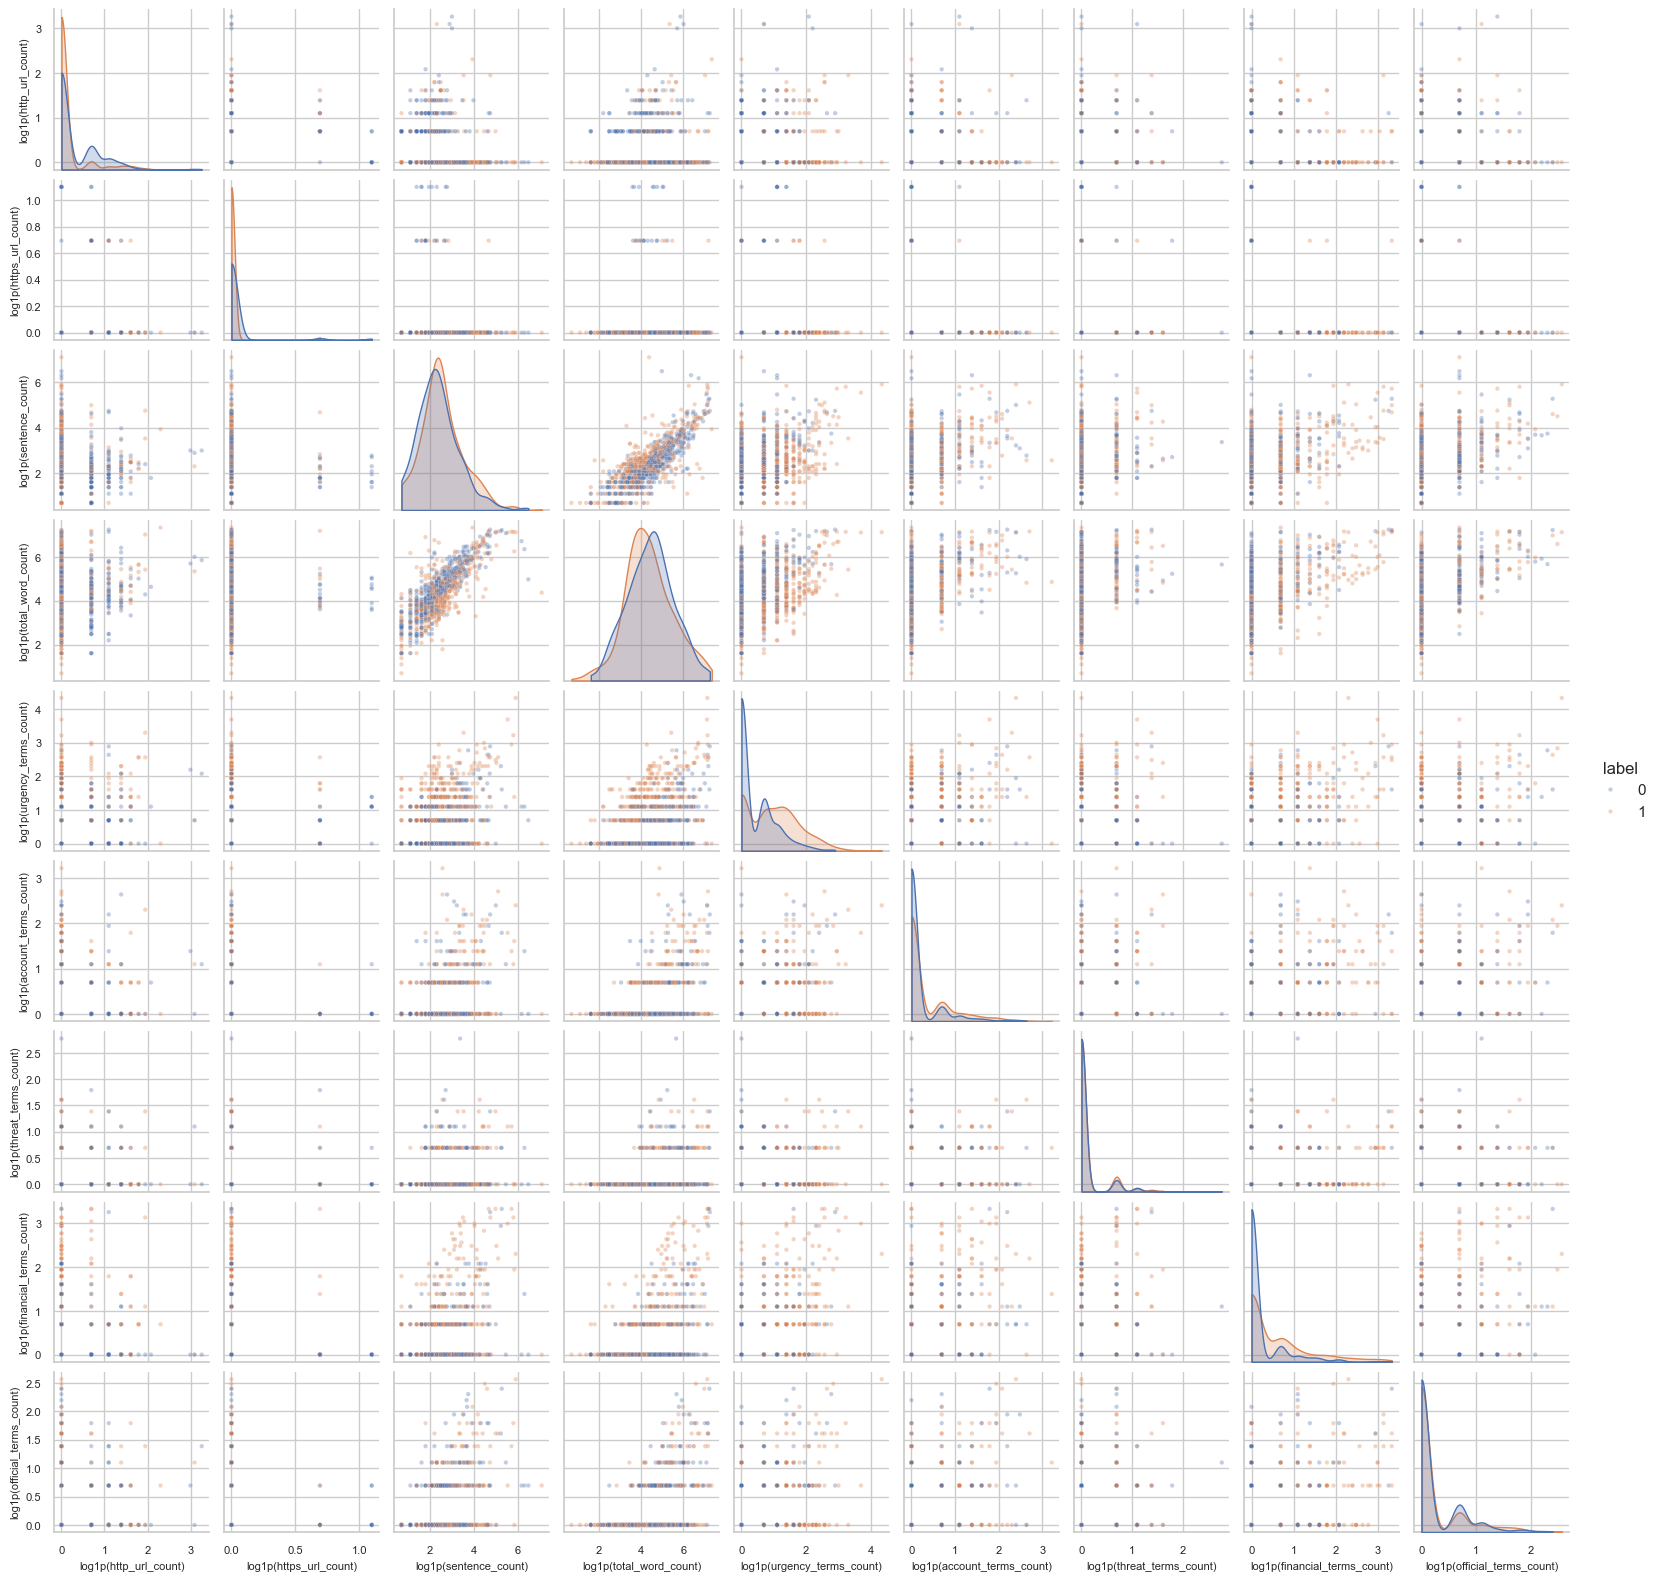

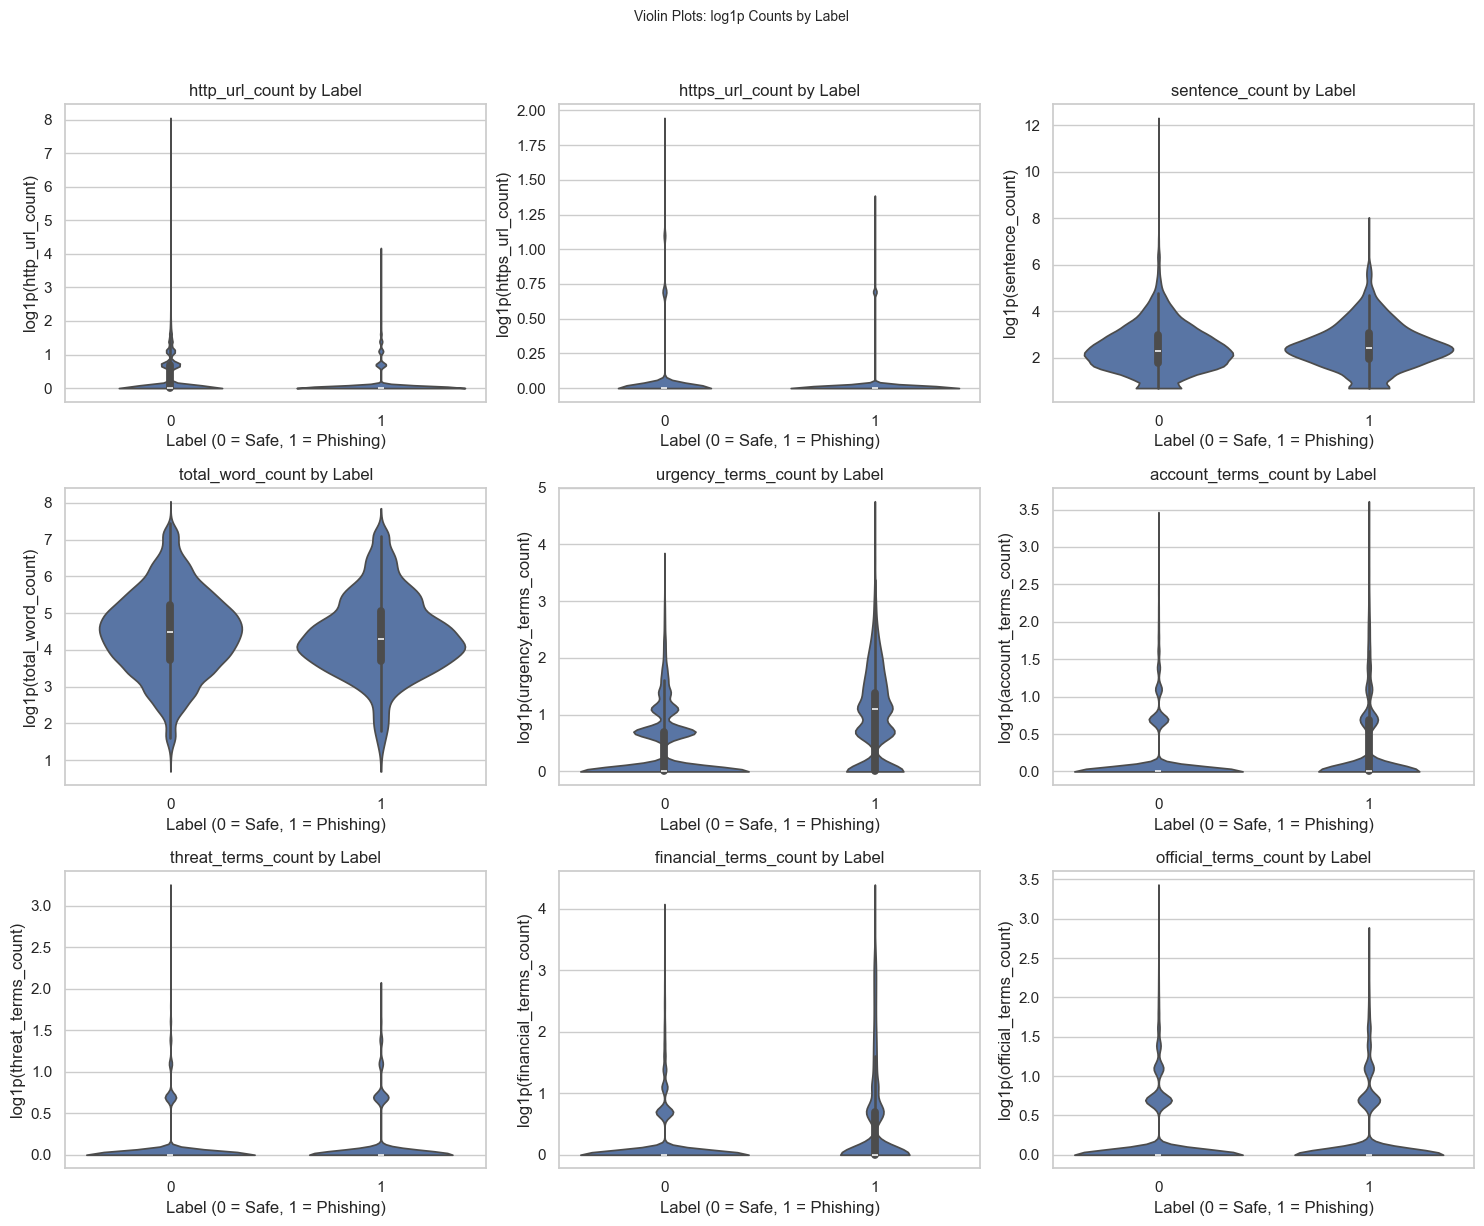

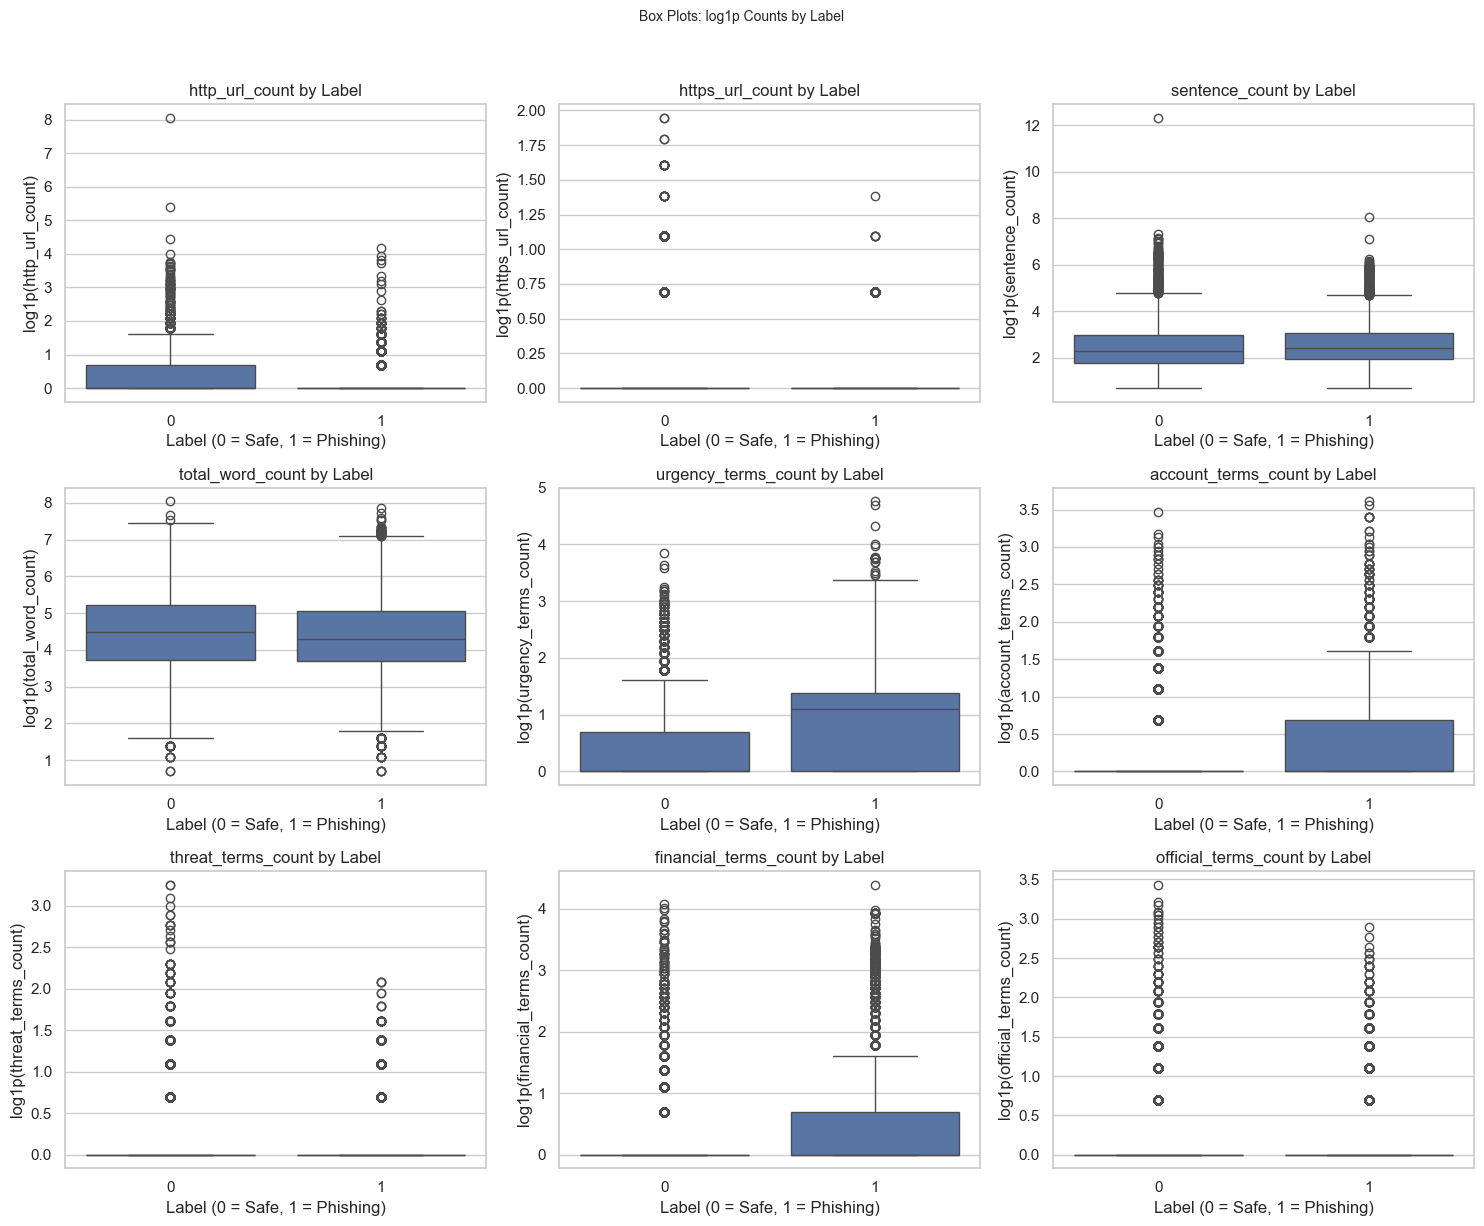

Performing KDE Analysis...


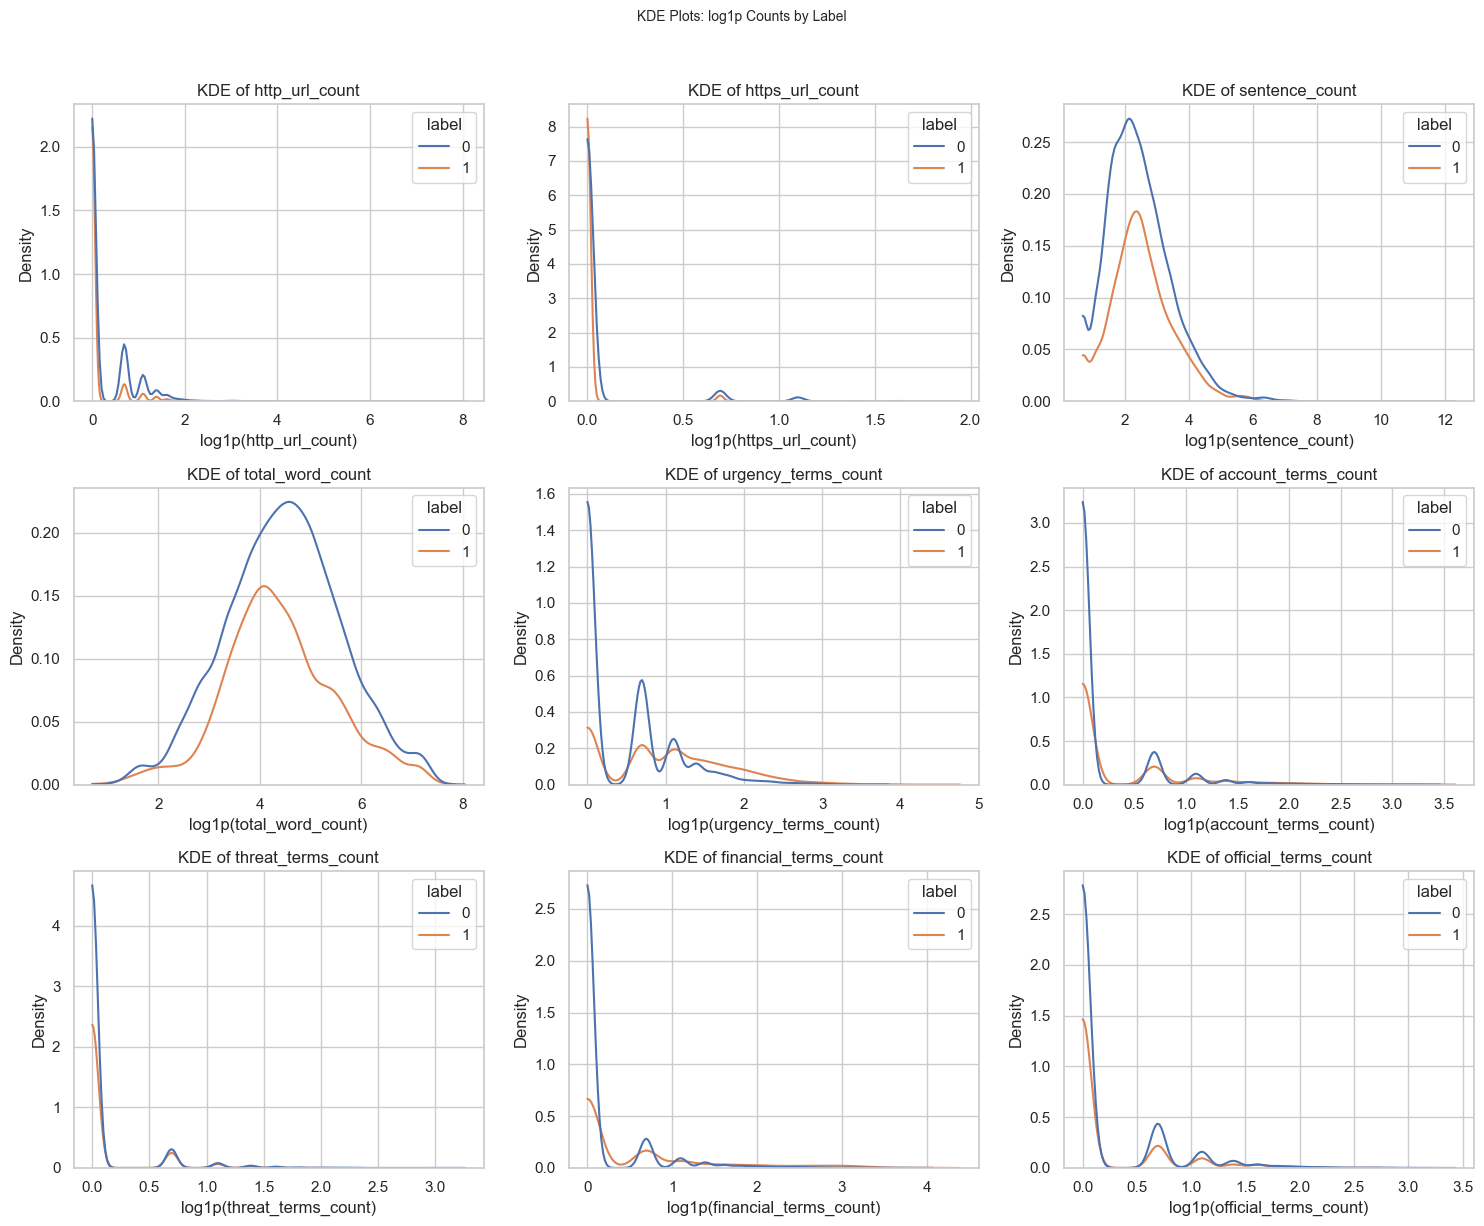

In [31]:
# Pass the full transformed corpus; each helper selects the nine counts and label.
analyze_phishing_email_Univariate_data(corpus_eda)
analyze_phishing_email_Bivariate_data(corpus_eda, include_kde=True)


#### So using these features alone will not give us good results and we have seen it in earlier weeks. So we are agumenting these with TF-IDF based on the contents  


In [32]:
# Lets drop the corpus_eda datframe to save memory since we have already performed the analysis and have the results.

del corpus_eda

## 7. Create the augmented feature vector: TF-IDF + nine engineered features

In [33]:
# Create the reusable raw augmented vector and preserve a catalog of its column order.
# Sparse horizontal stacking keeps the 5,000 TF-IDF columns from becoming a dense matrix.

assert EFFECTIVE_STOP_WORDS <= set(stopwords.words('english'))
assert EFFECTIVE_STOP_WORDS.isdisjoint(PROTECTED_FEATURE_WORDS)
assert tfidf_vectorizer.get_params()['stop_words'] == sorted(EFFECTIVE_STOP_WORDS)
assert EFFECTIVE_STOP_WORDS.isdisjoint(tfidf_vocabulary_words)

# Append the nine original count features in the declared order; keep everything sparse.
X_train_counts = sparse.csr_matrix(train_df[COUNT_FEATURE_COLUMNS].to_numpy(dtype=np.float32))
X_test_counts = sparse.csr_matrix(test_df[COUNT_FEATURE_COLUMNS].to_numpy(dtype=np.float32))
count_feature_names = np.array(['count__' + name for name in COUNT_FEATURE_COLUMNS])

X_train_augmented = sparse.hstack([X_train_tfidf, X_train_counts], format='csr', dtype=np.float32)
X_test_augmented = sparse.hstack([X_test_tfidf, X_test_counts], format='csr', dtype=np.float32)
X_holdout_augmented = X_test_augmented
augmented_feature_names = np.concatenate([tfidf_feature_names, count_feature_names])
augmented_feature_catalog = pd.DataFrame({
    'column_index': np.arange(len(augmented_feature_names)),
    'feature_name': augmented_feature_names,
    'feature_type': ['TF-IDF'] * len(tfidf_terms) + ['Count'] * len(COUNT_FEATURE_COLUMNS),
})
# Aliases used by exports and modeling.
X_train, X_test = X_train_augmented, X_test_augmented
X_holdout = X_holdout_augmented
feature_names = augmented_feature_names
feature_catalog = augmented_feature_catalog

# Verify the vector size, feature order, and row alignment before modeling.
assert len(COUNT_FEATURE_COLUMNS) == 9
assert X_train_augmented.shape == (len(y_train), len(augmented_feature_names))
assert X_test_augmented.shape == (len(y_test), len(augmented_feature_names))
assert len(augmented_feature_names) == X_train_tfidf.shape[1] + 9
assert list(augmented_feature_names[-9:]) == list(count_feature_names)
assert len(set(augmented_feature_names)) == len(augmented_feature_names)
for matrix in (X_train_augmented, X_test_augmented):
    assert sparse.isspmatrix_csr(matrix)
    assert matrix.dtype == np.float32
    assert np.isfinite(matrix.data).all()

augmentation_summary = pd.DataFrame({
    'rows': [X_train_augmented.shape[0], X_test_augmented.shape[0]],
    'TF-IDF features': [X_train_tfidf.shape[1], X_test_tfidf.shape[1]],
    'additional count features': [len(COUNT_FEATURE_COLUMNS)] * 2,
    'augmented features': [X_train_augmented.shape[1], X_test_augmented.shape[1]],
}, index=['Training', 'Holdout / test'])
print(f'TF-IDF uses {len(EFFECTIVE_STOP_WORDS)} effective NLTK stopwords; feature-word overlap: 0.')
display(augmentation_summary)
print('The nine appended features and their positions in the new vector:')
display(augmented_feature_catalog.tail(9))


TF-IDF uses 172 effective NLTK stopwords; feature-word overlap: 0.


,rows,TF-IDF features,additional count features,augmented features
Training,14109,5000,9,5009
Holdout / test,3402,5000,9,5009


The nine appended features and their positions in the new vector:


,column_index,feature_name,feature_type
5000,5000,count__http_url_count,Count
5001,5001,count__https_url_count,Count
5002,5002,count__sentence_count,Count
5003,5003,count__total_word_count,Count
5004,5004,count__urgency_terms_count,Count
5005,5005,count__account_terms_count,Count
5006,5006,count__threat_terms_count,Count
5007,5007,count__financial_terms_count,Count
5008,5008,count__official_terms_count,Count


## 8. Data ready for the next step

| Variable | Contents |
|---|---|
| `X_train_tfidf`, `X_test_tfidf` | Sparse TF-IDF features only |
| `X_train_counts`, `X_test_counts` | The original nine numeric count features |
| `X_train_augmented`, `X_test_augmented` | New sparse vectors: TF-IDF followed by nine raw count features |
| `X_train`, `X_test`, `X_holdout` | Compatible aliases for the augmented matrices |
| `augmented_feature_names`, `augmented_feature_catalog` | Ordered names and positions in the new vector |
| `y_train`, `y_test` | Aligned labels; Safe = 0, Phishing = 1 |
| `tfidf_terms`, `feature_names`, `feature_catalog` | Column names in matrix order |
| `tfidf_train_df`, `tfidf_test_df` | Named sparse TF-IDF DataFrames |
| `tfidf_vectorizer` | Fitted training vocabulary and IDF weights |
| `train_df`, `test_df` | Text, count features, labels, and source-row metadata |
| `groups_train`, `groups_test`, `cv_splits` | Group IDs and three training CV splits |
| `corpus_eda` | Full corpus copy with nine log1p-transformed count columns and the original label/text/metadata |
| `count_feature_summary`, `count_class_comparison` | Full-corpus summaries of the nine log1p count features |

`X_holdout` and `y_holdout` are aliases for the test partition. Row position `i`
in each matrix matches position `i` in its labels and source DataFrame.

The prepared matrices can be used for training and final holdout evaluation.
For cross-validation or tuning, use `cv_splits` with a pipeline that fits
a new TF-IDF vectorizer inside each fold using `train_df[TEXT_COLUMN]`. Using the
already fitted TF-IDF matrix for CV would expose validation-fold vocabulary and
IDF statistics. Keep the holdout separate during feature and model choices.
Reference: [scikit-learn guidance on preventing data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).

The shared classification methods below implement this pipeline using `train_df` as
input. TF-IDF is followed by the same nine raw count features; count scaling is
not needed for tree split thresholds. The pipeline clones the TF-IDF settings
and refits preprocessing without changing the prepared matrices or vectorizer.


In [34]:
# Final shape, alignment, and numeric checks. No classifier is trained here.
assert X_train.shape == (len(y_train), len(feature_names))
assert X_test.shape == (len(y_test), len(feature_names))
assert len(tfidf_terms) == X_train_tfidf.shape[1] == X_test_tfidf.shape[1]
assert len(np.unique(feature_names)) == len(feature_names)
assert X_train.shape[1] == X_train_tfidf.shape[1] + len(COUNT_FEATURE_COLUMNS)
for matrix in (X_train_tfidf, X_test_tfidf, X_train_counts, X_test_counts, X_train, X_test):
    assert sparse.isspmatrix_csr(matrix)
    assert matrix.dtype == np.float32
    assert np.isfinite(matrix.data).all()
    assert (matrix.data >= 0).all()
assert np.array_equal(y_train, train_df[TARGET_COLUMN].to_numpy())
assert np.array_equal(y_test, test_df[TARGET_COLUMN].to_numpy())

ready_summary = pd.DataFrame([
    {'feature_set': 'TF-IDF only', 'training_rows': X_train_tfidf.shape[0],
     'holdout_rows': X_test_tfidf.shape[0], 'features': X_train_tfidf.shape[1]},
    {'feature_set': 'Nine count features', 'training_rows': X_train_counts.shape[0],
     'holdout_rows': X_test_counts.shape[0], 'features': X_train_counts.shape[1]},
    {'feature_set': 'TF-IDF + counts (X_train / X_test)', 'training_rows': X_train.shape[0],
     'holdout_rows': X_test.shape[0], 'features': X_train.shape[1]},
])
display(ready_summary)
print('Data preparation and analysis complete. The matrices and labels are ready.')


,feature_set,training_rows,holdout_rows,features
0,TF-IDF only,14109,3402,5000
1,Nine count features,14109,3402,9
2,TF-IDF + counts (X_train / X_test),14109,3402,5009


Data preparation and analysis complete. The matrices and labels are ready.


## 9. Shared preparation, tuning, and evaluation methods

These helpers are defined here and called later with `train_df`, grouped `cv_splits`, and holdout `test_df`.

1. **Prepare features — `make_tree_features()`:** Define the transformer combining TF-IDF and nine raw counts for each classifier.
2. **Validate inputs — `validate_tuning_inputs()`:** Check labels, predictor columns, CV indices, and group separation before tuning.
3. **Tune — `tune_classifier()`:** Fit TF-IDF within each training fold, select the best mean phishing F1, and refit the pipeline on all training rows.
4. **Report CV — `build_model_results()`:** Summarize each parameter combination's mean scores and fit time.
5. **Evaluate and summarize:** `evaluate_classifier()` scores `test_df` without fitting; `build_holdout_record()` combines its results with CV scores, timings, and tree details.
6. **Plot — `plot_classifier_evaluation()`:** Optionally display confusion matrix, ROC, and precision-recall charts.

Models receive augmented features with original counts; `log1p` remains for EDA only.


In [35]:
# These will be need for classification and comparing perfromance of different models and hyperparameter tuning.
import json
import time
from tempfile import TemporaryDirectory

import joblib
from joblib import Memory, parallel_config
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.model_selection import GridSearchCV, ParameterGrid
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, root_mean_squared_error, roc_auc_score, average_precision_score,
    classification_report, confusion_matrix, make_scorer,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
)


In [36]:
def make_tree_features(vectorizer, *, text_column="word_text", count_columns=None):
    """Build an unfitted transformer combining fresh TF-IDF with optional raw counts.
    
    Args:
        vectorizer (TfidfVectorizer): Settings template; learned vocabulary and IDF are discarded.
        text_column (str): Prepared DataFrame column containing text.
        count_columns (sequence[str] | None): Unique numeric columns; None uses TF-IDF only.
    
    Returns:
        ColumnTransformer: TF-IDF followed by counts; other columns are dropped; output is sparse for this dataset.
    
    Raises:
        TypeError or ValueError: Count columns are a string, duplicated, or include text_column.
    """
    if isinstance(count_columns, str):
        raise TypeError("count_columns must be a sequence of names, not a string.")
    columns = list(count_columns) if count_columns is not None else []
    if text_column in columns or len(set(columns)) != len(columns):
        raise ValueError("Count columns must be unique and exclude the text column.")

    # Fit fresh vocabulary and IDF within each training fold.
    transformers = [("tfidf", clone(vectorizer), text_column)]
    if columns:
        transformers.append(("counts", "passthrough", columns))
    return ColumnTransformer(transformers, remainder="drop", sparse_threshold=1.0)


In [37]:
def validate_tuning_inputs(pipeline, training_frame, cv_splits, target_column, group_column):
    """Return labels and CV splits after checking predictors, labels, and group separation.

    Splits use positional indices into training_frame; invalid inputs raise ValueError.
    """
    labels = training_frame[target_column].to_numpy()
    groups = training_frame[group_column].to_numpy()
    if pd.isna(labels).any() or set(labels) != {0, 1}:
        raise ValueError("Training labels must contain both Safe=0 and Phishing=1.")
    if pd.isna(groups).any():
        raise ValueError("Training group IDs cannot be missing.")

    # Exclude labels and metadata from predictors.
    feature_transformer = pipeline.named_steps["features"]
    forbidden_columns = {target_column, group_column, "input_row", "content_hash", "copies"}
    for _, _, columns in feature_transformer.transformers:
        selected = [columns] if isinstance(columns, str) else list(columns)
        if forbidden_columns.intersection(selected):
            raise ValueError("The feature pipeline includes a label or metadata column.")

    splits = list(cv_splits)
    if len(splits) < 2:
        raise ValueError("Provide at least two grouped cross-validation splits.")
    # Require valid positions, both classes, and separate rows/groups in each fold.
    for fold, (fit_idx, valid_idx) in enumerate(splits, start=1):
        fit_idx, valid_idx = np.asarray(fit_idx), np.asarray(valid_idx)
        for indices in (fit_idx, valid_idx):
            if (indices.ndim != 1 or indices.dtype.kind not in "iu" or len(indices) == 0
                    or np.any(indices < 0) or np.any(indices >= len(training_frame))
                    or len(np.unique(indices)) != len(indices)):
                raise ValueError(f"Fold {fold} has invalid row indices for training_frame.")
            if set(labels[indices]) != {0, 1}:
                raise ValueError(f"Fold {fold} needs both classes in fit and validation rows.")
        if set(fit_idx).intersection(valid_idx):
            raise ValueError(f"Fold {fold} shares rows between fit and validation.")
        if set(groups[fit_idx]).intersection(groups[valid_idx]):
            raise ValueError(f"Fold {fold} shares email groups between fit and validation.")
    return labels, splits


In [38]:
def tune_classifier(
    pipeline, training_frame, cv_splits, param_grid, *,
    target_column="label", group_column="group_id", n_jobs=1, verbose=0,
    return_train_score=False,
):
    """Tune grouped CV and refit the pipeline with the best mean phishing F1.

    Use prepared training rows, positional CV splits, and pipeline-prefixed parameters.
    Options set label/group columns, parallel jobs, verbosity, and training-score reporting.
    Returns fitted GridSearchCV with CV scores/timings and elapsed_seconds_.
    TF-IDF fits within each fold; RMSE scores are negative; invalid inputs raise ValueError.
    """
    labels, splits = validate_tuning_inputs(
        pipeline, training_frame, cv_splits, target_column, group_column,
    )

    # Record all metrics; select the best candidate by mean validation F1.
    scoring = {
        "f1": make_scorer(f1_score, pos_label=1, zero_division=0),
        "precision": make_scorer(precision_score, pos_label=1, zero_division=0),
        "recall": make_scorer(recall_score, pos_label=1, zero_division=0),
        "roc_auc": make_scorer(roc_auc_score, response_method="predict_proba"),
        "average_precision": make_scorer(average_precision_score, response_method="predict_proba"),
        "balanced_accuracy": "balanced_accuracy",
        "rmse": "neg_root_mean_squared_error",  # RMSE of predicted 0/1 labels.
    }
    search = GridSearchCV(
        estimator=clone(pipeline), param_grid=param_grid, scoring=scoring,
        refit="f1", cv=splits, n_jobs=n_jobs, return_train_score=return_train_score,
        error_score="raise", verbose=verbose,
    )
    start = time.perf_counter()
    search.fit(training_frame, labels)
    search.elapsed_seconds_ = time.perf_counter() - start
    return search


In [39]:
def plot_classifier_evaluation(labels, scores, matrix, name):
    """Display confusion matrix, ROC, and precision-recall charts without fitting.

    scores are Phishing=1 probabilities; matrix is ordered [[TN, FP], [FN, TP]].
    """
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    ConfusionMatrixDisplay(matrix, display_labels=["Safe", "Phishing"]).plot(
        ax=axes[0], cmap="Blues", colorbar=False,
    )
    RocCurveDisplay.from_predictions(labels, scores, name=name, ax=axes[1])
    PrecisionRecallDisplay.from_predictions(labels, scores, name=name, ax=axes[2])
    axes[0].set_title(f"{name}: confusion matrix")
    axes[1].set_title("ROC using phishing probabilities")
    axes[2].set_title("Precision-recall using phishing probabilities")
    plt.tight_layout()
    plt.show()


In [40]:
def evaluate_classifier(
    fitted_model, evaluation_frame, *, target_column="label", name="Classifier", plot=True,
):
    """Evaluate a fitted pipeline/search on prepared rows with Safe=0 and Phishing=1.

    target_column supplies labels; name labels results; plot enables three evaluation charts.
    Return a dict of metrics, classification_report, confusion_matrix, predictions, and probability_scores.
    RMSE uses predicted labels; ROC-AUC/AP use phishing probabilities. No fitting occurs.
    Raise ValueError if evaluation labels or model classes do not contain exactly 0 and 1.
    """
    labels = evaluation_frame[target_column].to_numpy()
    if pd.isna(labels).any() or set(labels) != {0, 1}:
        raise ValueError("Evaluation requires both Safe=0 and Phishing=1 for ROC-AUC.")
    if not np.array_equal(fitted_model.classes_, np.array([0, 1])):
        raise ValueError("The fitted model must use Safe=0 and Phishing=1.")

    predictions = fitted_model.predict(evaluation_frame)
    scores = fitted_model.predict_proba(evaluation_frame)[:, 1]
    metrics = {
        "model": name, "rows": len(labels),
        "accuracy": accuracy_score(labels, predictions),
        "rmse": root_mean_squared_error(labels, predictions),
        "error_rate": np.mean(labels != predictions),
        "balanced_accuracy": balanced_accuracy_score(labels, predictions),
        "precision": precision_score(labels, predictions, zero_division=0),
        "recall": recall_score(labels, predictions, zero_division=0),
        "f1": f1_score(labels, predictions, zero_division=0),
        "roc_auc": roc_auc_score(labels, scores),
        "average_precision": average_precision_score(labels, scores),
    }
    report = pd.DataFrame(classification_report(
        labels, predictions, labels=[0, 1], target_names=["Safe", "Phishing"],
        output_dict=True, zero_division=0,
    )).T
    matrix = confusion_matrix(labels, predictions, labels=[0, 1])
    if plot:
        plot_classifier_evaluation(labels, scores, matrix, name)
    return {
        "metrics": metrics, "classification_report": report,
        "confusion_matrix": matrix, "predictions": predictions, "probability_scores": scores,
    }


In [41]:
def build_model_results(search, model_name="Classifier"):
    """Return an unrounded, eight-column CV summary with one row per parameter combination.
    
    Args:
        search (GridSearchCV): Fitted output of tune_classifier with its named CV metrics.
        model_name (str): Model label repeated on each row.
    
    Returns:
        pd.DataFrame: Parameters without model__ prefixes, mean CV scores, positive label RMSE, and mean fold-fit seconds.
    """
    cv = pd.DataFrame(search.cv_results_)
    return pd.DataFrame({
        'model': model_name,
        'hyper param': [{key.removeprefix('model__'): value for key, value in parameters.items()}
                        for parameters in cv['params']],
        'CV_rmse': -cv['mean_test_rmse'],
        'CV_ROC_AUC': cv['mean_test_roc_auc'],
        'CV Avg Precision': cv['mean_test_precision'],
        'CV_Avg_recall': cv['mean_test_recall'],
        'CV_Avg_F1score': cv['mean_test_f1'],
        'CV Fit time': cv['mean_fit_time'],
    })


In [42]:
def build_holdout_record(
    name, search, estimator, result, *, evaluation_seconds,
    training_rows, test_rows, selected_model_name,
):
    """Validate one evaluation and return its CV/holdout metrics, timings, and tree details.

    Reuse fitted search results and predictions; no fitting or prediction occurs here.
    """
    metrics = result['metrics']
    tn, fp, fn, tp = result['confusion_matrix'].ravel()
    assert tn + fp + fn + tp == test_rows
    np.testing.assert_allclose(metrics['rmse'] ** 2, 1 - metrics['accuracy'])
    assert np.isfinite(result['probability_scores']).all()

    trees = [estimator] if isinstance(estimator, DecisionTreeClassifier) else estimator.estimators_
    best, scores = search.best_index_, search.cv_results_
    return {
        'model': name, 'hyper param': search.best_params_,
        'CV_RMSE': -scores['mean_test_rmse'][best], 'CV_F1': search.best_score_,
        'CV_ROC_AUC': scores['mean_test_roc_auc'][best],
        'CV_Precision': scores['mean_test_precision'][best],
        'CV_Recall': scores['mean_test_recall'][best],
        'CV_F1_Std': scores['std_test_f1'][best],
        'CV_Mean_Fit_Time_Seconds': scores['mean_fit_time'][best],
        'Test_RMSE': metrics['rmse'], 'Accuracy': metrics['accuracy'],
        'Balanced_Accuracy': metrics['balanced_accuracy'],
        'Precision': metrics['precision'], 'Recall': metrics['recall'], 'F1': metrics['f1'],
        'ROC_AUC': metrics['roc_auc'], 'Average_precision': metrics['average_precision'],
        'Test_Error_Rate': metrics['error_rate'], 'Fit_Time_Seconds': search.refit_time_,
        'Search_Time_Seconds': search.elapsed_seconds_, 'Evaluation_Time_Seconds': evaluation_seconds,
        'True_Negatives': int(tn), 'False_Positives': int(fp),
        'False_Negatives': int(fn), 'True_Positives': int(tp),
        'Fitted_Trees': len(trees),
        'Max_Component_Depth': max(tree.get_depth() for tree in trees),
        'Total_Leaves': sum(tree.get_n_leaves() for tree in trees),
        'Features': estimator.n_features_in_, 'Training_Rows': training_rows, 'Test_Rows': test_rows,
        'Selected_Overall_By_CV': name == selected_model_name,
    }


## 10. Decision-tree classification

The pipeline combines TF-IDF and selected raw counts before fitting a decision tree.
The quick grid tests **max_depth = 5, 10, 20, None** (four configurations).
The expanded grid also tests **min_samples_leaf = 1, 5, 10** (12 configurations).
`None` leaves depth unrestricted; compare training and validation F1 for overfitting.

In this section we define a decision-tree pipeline using TF-IDF plus nine raw count features. It prepares four tree-depth configurations for the quick search, or 12 depth-and-leaf-size combinations for the expanded search. Tuning runs later using grouped cross-validation; training and validation F1 help identify overfitting.


In [43]:
def create_decision_tree(
    vectorizer, *, text_column="word_text", count_columns=None,
    criterion="gini", max_depth=None, min_samples_split=2, min_samples_leaf=1,
    max_features=None, class_weight=None, ccp_alpha=0.0, random_state=42,
):
    """Build an unfitted TF-IDF + optional raw counts -> decision-tree pipeline.
    
    Args:
        vectorizer (TfidfVectorizer): Settings template cloned for preprocessing within each fold.
        text_column (str): Prepared input text column.
        count_columns (sequence[str] | None): Counts appended after TF-IDF; None uses text only.
        criterion (str): Split impurity measure: gini, entropy, or log_loss.
        max_depth (int | None): Tree depth limit; None leaves depth unrestricted.
        min_samples_split (int | float): Minimum row count or fraction required to split a node.
        min_samples_leaf (int | float): Minimum row count or fraction required in a leaf.
        max_features (int | float | str | None): Features considered per split; None uses all.
        class_weight (dict | str | None): Class weights, 'balanced', or no weighting.
        ccp_alpha (float): Non-negative pruning strength; larger values prune more.
        random_state (int): Seed for reproducible tree fitting.
    
    Returns:
        Pipeline: Unfitted features -> model; fitted predict gives (n_rows,) labels and predict_proba gives (n_rows, 2) scores in classes_ order.
    """
    return Pipeline([
        ("features", make_tree_features(
            vectorizer, text_column=text_column, count_columns=count_columns,
        )),
        ("model", DecisionTreeClassifier(
            criterion=criterion, max_depth=max_depth,
            min_samples_split=min_samples_split, min_samples_leaf=min_samples_leaf,
            max_features=max_features, class_weight=class_weight,
            ccp_alpha=ccp_alpha, random_state=random_state,
        )),
    ])


In [44]:
# Four configurations in quick mode; 12 when depth and leaf size are varied together.
decision_tree_quick_grid = {
    'model__max_depth': [5, 10, 20, None],
}
decision_tree_expanded_grid = {
    'model__max_depth': [5, 10, 20, None],
    'model__min_samples_leaf': [1, 5, 10],
}


## 11. Random forest with bootstrap bagging

The pipeline fits trees on bootstrap samples (`bootstrap=True`) and averages their
class probabilities. `max_features='sqrt'` selects feature subsets at each split;
`max_samples=None` gives each bootstrap sample the training set's row count.

The quick grid tests **50, 100, 200, 300 trees**. The expanded grid tests
**100, 200, 300 trees × depth 20/None × leaf size 1/5** (12 configurations).
Keep forest `n_jobs=1` because GridSearchCV parallelizes the outer search.


In [45]:
def create_random_forest(
    vectorizer, *, text_column="word_text", count_columns=None, n_estimators=100,
    max_depth=None, min_samples_split=2, min_samples_leaf=1, max_features="sqrt",
    max_samples=None, class_weight=None, criterion="gini", random_state=42, n_jobs=1,
):
    """Build an unfitted TF-IDF + optional raw counts -> bootstrap random-forest pipeline.
    
    Args:
        vectorizer (TfidfVectorizer): Settings template cloned for preprocessing within each fold.
        text_column (str): Prepared input text column.
        count_columns (sequence[str] | None): Counts appended after TF-IDF; None uses text only.
        n_estimators (int): Number of bootstrap-trained trees.
        max_depth (int | None): Per-tree depth limit; None leaves depth unrestricted.
        min_samples_split (int | float): Minimum row count or fraction required to split a node.
        min_samples_leaf (int | float): Minimum row count or fraction required in a leaf.
        max_features (int | float | str | None): Features considered per split; 'sqrt' uses the square root of the total.
        max_samples (int | float | None): Bootstrap sample count or fraction; None uses the training-row count.
        class_weight (dict | str | None): Class weights, 'balanced', 'balanced_subsample', or no weighting.
        criterion (str): Split impurity measure: gini, entropy, or log_loss.
        random_state (int): Seed for bootstrap sampling and tree fitting.
        n_jobs (int): Forest workers; keep 1 when the outer search runs in parallel.
    
    Returns:
        Pipeline: Unfitted features -> model with bootstrap=True; fitted probabilities average across trees in classes_ order.
    """
    return Pipeline([
        ("features", make_tree_features(
            vectorizer, text_column=text_column, count_columns=count_columns,
        )),
        ("model", RandomForestClassifier(
            n_estimators=n_estimators, max_depth=max_depth,
            min_samples_split=min_samples_split, min_samples_leaf=min_samples_leaf,
            max_features=max_features, bootstrap=True, max_samples=max_samples,
            class_weight=class_weight, criterion=criterion,
            random_state=random_state, n_jobs=n_jobs,
        )),
    ])


In [46]:
# bootstrap=True is fixed in the factory; every candidate uses bootstrap bagging.
random_forest_quick_grid = {
    'model__n_estimators': [50, 100, 200, 300],
}
random_forest_expanded_grid = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [20, None],
    'model__min_samples_leaf': [1, 5],
}


## 12. Boosting with AdaBoost

AdaBoost fits weak decision tree models **sequentially**, with
earlier learners are weak classifiers and misclassify and combining their predictions with learned
weights. The default weak learner is a **decision stump (`max_depth=1`)**. This
workflow uses boosting; learning rate controls how strongly
each learner contributes. Boosting can stop early if a learner fits perfectly.

The quick grid varies **25, 50, 100, 200 boosting rounds** at `learning_rate=1.0`
with stumps. The expanded grid tests **50/100/200 rounds × learning rate 0.1/1.0 ×
weak-tree depth 1/2**, giving 12 configurations. Nested weak-learner parameters
use names such as `model__estimator__max_depth`.

In [47]:
def create_adaboost(
    vectorizer, *, text_column="word_text", count_columns=None, n_estimators=50,
    learning_rate=1.0, weak_max_depth=1, weak_min_samples_leaf=1, random_state=42,
):
    """Build a TF-IDF/count pipeline with AdaBoost over shallow decision trees.

    Parameters
    ----------
    vectorizer : sklearn.feature_extraction.text.TfidfVectorizer
        Settings template; learned vocabulary/IDF are not reused across folds.
    text_column : str, default 'word_text'
        Prepared DataFrame text column.
    count_columns : sequence[str] | None, default None
        Raw count predictors appended after TF-IDF.
    n_estimators : int, default 50
        Maximum boosting rounds; actual fitted learner count can be smaller.
    learning_rate : float, default 1.0
        Positive multiplier for learner contributions; tune jointly with rounds.
    weak_max_depth : int, default 1
        Maximum depth of each weak decision tree (1 means decision stump).
    weak_min_samples_leaf : int, default 1
        Minimum rows in each weak tree leaf.
    random_state : int, default 42
        Seed forwarded to the weak learner and boosting ensemble.

    Returns
    -------
    sklearn.pipeline.Pipeline
        Unfitted features -> model pipeline with AdaBoostClassifier. After fitting,
        predict returns integer labels of shape (n_rows,); predict_proba returns
        (n_rows, 2) estimates ordered by classes_. Estimates are not separately
        calibrated. Nested grid settings can override estimator__max_depth.
    """
    weak_tree = DecisionTreeClassifier(
        max_depth=weak_max_depth, min_samples_leaf=weak_min_samples_leaf,
        random_state=random_state,
    )
    boosting = AdaBoostClassifier(
        estimator=weak_tree, n_estimators=n_estimators,
        learning_rate=learning_rate, random_state=random_state,
    )
    # The installed sklearn API exposes algorithm; request discrete SAMME explicitly.
    # Also allow versions where SAMME is the only algorithm and the keyword is absent.
    if 'algorithm' in boosting.get_params():
        boosting.set_params(algorithm='SAMME')
    return Pipeline([
        ("features", make_tree_features(
            vectorizer, text_column=text_column, count_columns=count_columns,
        )),
        ("model", boosting),
    ])


In [48]:
# Four round counts in quick mode; expanded mode also varies shrinkage and weak-tree depth.
adaboost_quick_grid = {
    'model__n_estimators': [25, 50, 100, 200],
}
adaboost_expanded_grid = {
    'model__n_estimators': [50, 100, 200],
    'model__learning_rate': [0.1, 1.0],
    'model__estimator__max_depth': [1, 2],
}


## 13. Run the three model searches in order

The default `SEARCH_MODE='quick'` gives **four configurations per family**:
12 candidate rows, **36 CV fits and three full-training refits**. Each quick grid
varies one main control while holding other parameters at defaults.
 `SEARCH_MODE='expanded'` selects 12 configurations per family:
36 candidate rows, **108 CV fits and three refits**. This notebook runs only the
selected mode; the expanded search is an optional follow-up.

Execution order is **Decision Tree, Random Forest (Bagging), AdaBoost**. Each
family uses its own temporary preprocessing cache, preserving a fresh full-training
refit for timing. Up to four CV fits run concurrently; forest internals use one
worker. Training scores are optional and add prediction work, not extra fits.

`model_searches` stores fitted GridSearchCV objects, `model_cv_results_df` stores
all candidate/fold details, and `results_df` stores the single eight-column
candidate report. This section prepares those objects without displaying multiple
performance tables. **Saved outputs show the completed quick run.**

In [49]:
# Shared experiment controls: all families use the same data, feature definitions, and folds.
INCLUDE_COUNTS = True
SEARCH_MODE = 'quick'  # 'quick': 4 per family; 'expanded': 12 per family.
COLLECT_TRAIN_SCORES = True  # Set False to reduce per-fold prediction/scoring work.
SEARCH_JOBS = min(4, joblib.cpu_count())
SAVE_MODEL_ARTIFACTS = True
MODEL_ORDER = ['Decision Tree', 'Random Forest (Bagging)', 'AdaBoost']
MODELS_TO_RUN = MODEL_ORDER.copy()
count_columns_for_models = COUNT_FEATURE_COLUMNS if INCLUDE_COUNTS else None

model_candidates = {
    'Decision Tree': create_decision_tree(
        tfidf_vectorizer, text_column=TEXT_COLUMN, count_columns=count_columns_for_models,
        random_state=RANDOM_STATE,
    ),
    'Random Forest (Bagging)': create_random_forest(
        tfidf_vectorizer, text_column=TEXT_COLUMN, count_columns=count_columns_for_models,
        random_state=RANDOM_STATE, n_jobs=1,
    ),
    'AdaBoost': create_adaboost(
        tfidf_vectorizer, text_column=TEXT_COLUMN, count_columns=count_columns_for_models,
        random_state=RANDOM_STATE,
    ),
}
quick_param_grids = {
    'Decision Tree': decision_tree_quick_grid,
    'Random Forest (Bagging)': random_forest_quick_grid,
    'AdaBoost': adaboost_quick_grid,
}
expanded_param_grids = {
    'Decision Tree': decision_tree_expanded_grid,
    'Random Forest (Bagging)': random_forest_expanded_grid,
    'AdaBoost': adaboost_expanded_grid,
}
if SEARCH_MODE not in {'quick', 'expanded'}:
    raise ValueError("Choose SEARCH_MODE='quick' or 'expanded'.")
if (not MODELS_TO_RUN or len(set(MODELS_TO_RUN)) != len(MODELS_TO_RUN)
        or not set(MODELS_TO_RUN).issubset(MODEL_ORDER)):
    raise ValueError('Select unique model names from MODEL_ORDER.')
param_grids = quick_param_grids if SEARCH_MODE == 'quick' else expanded_param_grids
candidate_counts = {name: len(ParameterGrid(param_grids[name])) for name in MODELS_TO_RUN}
total_candidates = sum(candidate_counts.values())
MODEL_FILE_STEMS = {'Decision Tree': 'decision_tree',
                    'Random Forest (Bagging)': 'random_forest_bagging', 'AdaBoost': 'adaboost'}
RESULTS_DIR = Path(
    f'./artifacts/week6_tree_ensembles/{SEARCH_MODE}_grid_'
    f'{total_candidates}configs_tfidf_{MAX_FEATURES_TFIDF}'
)
for name in MODELS_TO_RUN:
    print(f'{name}: {candidate_counts[name]} configurations')
print(f'Total: {total_candidates} candidates × {len(cv_splits)} folds = '
      f'{total_candidates * len(cv_splits)} CV fits, plus {len(MODELS_TO_RUN)} refits.')


Decision Tree: 4 configurations
Random Forest (Bagging): 4 configurations
AdaBoost: 4 configurations
Total: 12 candidates × 3 folds = 36 CV fits, plus 3 refits.


In [50]:
# Run the configured searches and store their fitted pipelines and CV results.
RUN_MODEL_SEARCHES = True
model_searches = {}
selected_models = {}
model_cv_frames = {}
model_cv_results_df = pd.DataFrame()
results_df = pd.DataFrame()
selected_model_name = None
selected_model = None

if RUN_MODEL_SEARCHES:
    if SAVE_MODEL_ARTIFACTS:
        RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    with TemporaryDirectory(prefix='week6_ensemble_cv_') as cache_directory:
        with parallel_config(backend='loky', inner_max_num_threads=1):
            for model_name in MODELS_TO_RUN:
                stem = MODEL_FILE_STEMS[model_name]
                # Independent family caches make each full-training refit include fresh TF-IDF.
                memory = Memory(Path(cache_directory) / stem, verbose=0)
                candidate = clone(model_candidates[model_name]).set_params(memory=memory)
                print(f'Tuning {model_name} on {len(train_df):,} training rows...', flush=True)
                search = tune_classifier(
                    candidate, train_df, cv_splits, param_grids[model_name],
                    target_column=TARGET_COLUMN, n_jobs=SEARCH_JOBS, verbose=2,
                    return_train_score=COLLECT_TRAIN_SCORES,
                )
                # Fitted transformers are retained; predictions need no temporary fit cache.
                search.best_estimator_.set_params(memory=None)
                search.estimator.set_params(memory=None)
                model_searches[model_name] = search
                selected_models[model_name] = search.best_estimator_
                model_cv_frames[model_name] = pd.DataFrame(search.cv_results_)
                if SAVE_MODEL_ARTIFACTS:
                    joblib.dump(search, RESULTS_DIR / f'{stem}_search.joblib')
                    joblib.dump(search.best_estimator_, RESULTS_DIR / f'{stem}_best_pipeline.joblib')
                    model_cv_frames[model_name].to_csv(RESULTS_DIR / f'{stem}_cv_results.csv', index=False)
                print(f'{model_name} search completed in {search.elapsed_seconds_:.1f} seconds.', flush=True)

    # One row per candidate, all three families combined, with the same eight public columns.
    results_df = pd.concat(
        [build_model_results(model_searches[name], name) for name in MODELS_TO_RUN],
        ignore_index=True,
    )
    model_cv_results_df = pd.concat(
        [frame.assign(model=name) for name, frame in model_cv_frames.items()], ignore_index=True,
    )
    # Freeze overall selection using training CV before any holdout predictions.
    selected_model_name = max(model_searches, key=lambda name: model_searches[name].best_score_)
    selected_model = selected_models[selected_model_name]
    if SAVE_MODEL_ARTIFACTS:
        results_df.to_csv(RESULTS_DIR / 'model_results.csv', index=False)
        model_cv_results_df.to_csv(RESULTS_DIR / 'all_candidate_cv_results.csv', index=False)
        joblib.dump(selected_model, RESULTS_DIR / 'selected_pipeline.joblib')
else:
    print('No models fitted. Set RUN_MODEL_SEARCHES=True and execute this cell when ready.')


Tuning Decision Tree on 14,109 training rows...
Fitting 3 folds for each of 4 candidates, totalling 12 fits
[CV] END .................................model__max_depth=5; total time=   7.7s
[CV] END .................................model__max_depth=5; total time=   7.8s
[CV] END .................................model__max_depth=5; total time=   7.6s
[CV] END ................................model__max_depth=10; total time=   7.9s
[CV] END ................................model__max_depth=10; total time=   2.7s
[CV] END ................................model__max_depth=10; total time=   2.7s
[CV] END ................................model__max_depth=20; total time=   3.1s
[CV] END ................................model__max_depth=20; total time=   3.2s
[CV] END ................................model__max_depth=20; total time=   2.9s
[CV] END ..............................model__max_depth=None; total time=   3.4s
[CV] END ..............................model__max_depth=None; total time=   3.6s
[

## 14. Single results DataFrame and best configurations

`results_df` contains every tested configuration across all three model families.
The quick run produces **12 rows** with exactly these columns:
`model`, `hyper param`, `CV_rmse`, `CV_ROC_AUC`, `CV Avg Precision`,
`CV_Avg_recall`, `CV_Avg_F1score`, `CV Fit time`.

`CV Avg Precision` is mean **ordinary phishing precision across validation folds**,
not average precision (AP). Recall and F1 are also fold means. `CV_rmse` is the
mean fold RMSE of predicted 0/1 labels; the negative loss used by GridSearchCV is
converted back to positive RMSE. `CV Fit time` is mean fold-fit **seconds**, which
can include preprocessing cache hits and concurrent-worker effects.

Change the display controls to limit rows, models, or columns without deleting
results or retraining. Best configurations are printed **after the one table**,
using unrounded CV F1 rather than the filtered display. Full-training refit times
and holdout metrics are retained separately in `holdout_results_df` below.

In [51]:
# These settings control only the final presentation, never model fitting or selection.
DISPLAY_COLUMNS = [
    'model', 'hyper param', 'CV_rmse', 'CV_ROC_AUC', 'CV Avg Precision',
    'CV_Avg_recall', 'CV_Avg_F1score', 'CV Fit time',
]
DISPLAY_MODELS = None  # Example: ['Decision Tree', 'AdaBoost']; None shows all.
DISPLAY_TOP_N = None  # None shows every tested candidate.
DISPLAY_SORT_BY = ['model', 'CV_Avg_F1score']
DISPLAY_ASCENDING = [True, False]
best_configurations = {}

if model_searches:
    display_df = results_df.copy()
    if DISPLAY_MODELS is not None:
        display_df = display_df[display_df['model'].isin(DISPLAY_MODELS)]
    # Preserve the requested family order, while sorting candidate quality within each family.
    display_df['model'] = pd.Categorical(display_df['model'], categories=MODEL_ORDER, ordered=True)
    display_df = display_df.sort_values(DISPLAY_SORT_BY, ascending=DISPLAY_ASCENDING)
    if DISPLAY_TOP_N is not None:
        display_df = display_df.head(DISPLAY_TOP_N)
    with pd.option_context('display.max_columns', None, 'display.max_colwidth', None,
                           'display.max_rows', None):
        display(display_df.loc[:, DISPLAY_COLUMNS].round(4))

    print('Best configuration for each classifier (highest mean CV phishing F1):')
    for name in MODELS_TO_RUN:
        search = model_searches[name]
        best = search.best_index_
        parameters = {key.removeprefix('model__'): value for key, value in search.best_params_.items()}
        best_configurations[name] = {
            'hyper param': parameters, 'CV_Avg_F1score': float(search.best_score_),
            'CV_ROC_AUC': float(search.cv_results_['mean_test_roc_auc'][best]),
            'CV_rmse': float(-search.cv_results_['mean_test_rmse'][best]),
            'Fit_Time_Seconds': float(search.refit_time_),
        }
        print(f"  {name}: {parameters}; CV F1={search.best_score_:.6f}; "
              f"CV ROC-AUC={best_configurations[name]['CV_ROC_AUC']:.6f}; "
              f"full-training fit={search.refit_time_:.2f} s")
    print('Overall selection using training CV F1:', selected_model_name)
    if SAVE_MODEL_ARTIFACTS:
        _ = (RESULTS_DIR / 'best_configurations.json').write_text(json.dumps(best_configurations, indent=2))
else:
    print('No classification results yet. Run the search before displaying performance.')


,model,hyper param,CV_rmse,CV_ROC_AUC,CV Avg Precision,CV_Avg_recall,CV_Avg_F1score,CV Fit time
3,Decision Tree,{'max_depth': None},0.3044,0.9024,0.8719,0.8825,0.8772,1.8933
2,Decision Tree,{'max_depth': 20},0.3167,0.9285,0.8838,0.8437,0.8631,1.4010
1,Decision Tree,{'max_depth': 10},0.3752,0.9150,0.8216,0.7977,0.8094,2.6385
0,Decision Tree,{'max_depth': 5},0.4549,0.8383,0.9111,0.4967,0.6427,5.6772
7,Random Forest (Bagging),{'n_estimators': 300},0.1747,0.9954,0.9599,0.9584,0.9591,12.6480
6,Random Forest (Bagging),{'n_estimators': 200},0.1749,0.9953,0.9599,0.9582,0.9590,10.1460
5,Random Forest (Bagging),{'n_estimators': 100},0.1754,0.9950,0.9613,0.9561,0.9587,6.5205
4,Random Forest (Bagging),{'n_estimators': 50},0.1834,0.9940,0.9599,0.9497,0.9548,8.8741
11,AdaBoost,{'n_estimators': 200},0.2999,0.9725,0.9125,0.8406,0.8751,17.8203
10,AdaBoost,{'n_estimators': 100},0.3542,0.9554,0.8931,0.7560,0.8188,8.6386


Best configuration for each classifier (highest mean CV phishing F1):
  Decision Tree: {'max_depth': None}; CV F1=0.877193; CV ROC-AUC=0.902377; full-training fit=8.24 s
  Random Forest (Bagging): {'n_estimators': 300}; CV F1=0.959133; CV ROC-AUC=0.995432; full-training fit=19.35 s
  AdaBoost: {'n_estimators': 200}; CV F1=0.875087; CV ROC-AUC=0.972478; full-training fit=26.18 s
Overall selection using training CV F1: Random Forest (Bagging)


## 15. Selected-model performance, fit time, confusion matrices and AUC

Reuse each CV-selected pipeline on the same holdout rows; no models are refitted.

1. **Evaluate:** Call `evaluate_classifier()` once per model and retain predictions in `holdout_results`.
2. **Summarize:** `build_holdout_record()` checks each result and combines CV scores, holdout metrics, timings, and tree details into `holdout_results_df`.
3. **Save:** Optionally export the stored results and run settings in the next cell.
4. **Display:** Reuse the results for the existing tables, confusion matrices, and plots.

Fit time measures full-training refit; search time covers tuning; evaluation time
covers holdout prediction/scoring. Confusion matrices use `[[TN, FP], [FN, TP]]`.
ROC-AUC/AP use phishing probabilities; other classification metrics use predicted labels.


In [52]:
# Evaluate each CV-selected pipeline once; reuse its results in later tables and plots.
holdout_results = {}
holdout_results_df = pd.DataFrame()
performance_records = []

if model_searches:
    assert set(groups_train).isdisjoint(groups_test)
    assert np.array_equal(y_test, test_df[TARGET_COLUMN].to_numpy())
    expected_features = X_train_tfidf.shape[1] + len(count_columns_for_models or [])

    for name in MODELS_TO_RUN:
        search, pipeline = model_searches[name], selected_models[name]
        estimator = pipeline.named_steps['model']
        feature_names_fitted = pipeline.named_steps['features'].get_feature_names_out()
        assert estimator.n_features_in_ == len(feature_names_fitted) == expected_features

        start = time.perf_counter()
        result = evaluate_classifier(pipeline, test_df, target_column=TARGET_COLUMN, name=name, plot=False)
        evaluation_seconds = time.perf_counter() - start
        holdout_results[name] = result
        performance_records.append(build_holdout_record(
            name, search, estimator, result, evaluation_seconds=evaluation_seconds,
            training_rows=len(train_df), test_rows=len(test_df), selected_model_name=selected_model_name,
        ))

    holdout_results_df = pd.DataFrame(performance_records)
else:
    print('Holdout evaluation is waiting for the model searches.')


### Display the section results and confusion matrices from stored DataFrames

The first table has **one row per selected classifier**: Decision Tree, Random
Forest (Bagging), and AdaBoost. It reads `holdout_results_df` and shows the selected
hyperparameters, accuracy, precision, recall, F1, ROC-AUC, AP, test RMSE, and
full-training fit time in seconds. These are holdout metrics; Section 14 remains
the combined candidate **CV** results table.

Each model's numeric confusion matrix is then displayed as a labeled DataFrame,
reconstructed from that same row's TN, FP, FN, and TP counts and checked against
the stored evaluation matrix. **Rows are actual classes; columns are predicted
classes.** The Safe/Phishing order gives `[[TN, FP], [FN, TP]]`.

Edit `HOLDOUT_DISPLAY_COLUMNS` or `HOLDOUT_DISPLAY_MODELS` to control what is
shown. This cell only presents stored results; rerunning it does not train models,
generate predictions, or change any score. The plots follow these printed tables.


In [53]:
# Report this section's selected-model performance directly from its stored DataFrame.
HOLDOUT_DISPLAY_COLUMNS = [
    'model', 'hyper param', 'Accuracy', 'Precision', 'Recall', 'F1',
    'ROC_AUC', 'Average_precision', 'Test_RMSE', 'Fit_Time_Seconds',
]
HOLDOUT_DISPLAY_MODELS = None  # Example: ['Decision Tree', 'AdaBoost']; None shows all.
confusion_matrix_frames = {}  # Keep the labeled matrices available for reuse.

if not holdout_results_df.empty:
    # Work on a presentation copy and preserve the same model order as the searches.
    holdout_display_df = holdout_results_df.set_index('model').loc[MODELS_TO_RUN].reset_index()
    if HOLDOUT_DISPLAY_MODELS is not None:
        holdout_display_df = holdout_display_df[
            holdout_display_df['model'].isin(HOLDOUT_DISPLAY_MODELS)
        ].copy()
    # Shorter parameter names are only for display; the full saved results are unchanged.
    holdout_display_df['hyper param'] = holdout_display_df['hyper param'].map(
        lambda parameters: {key.removeprefix('model__'): value for key, value in parameters.items()}
    )
    print('Selected classifiers: holdout results (fit time in seconds)')
    with pd.option_context('display.max_columns', None, 'display.max_colwidth', None,
                           'display.max_rows', None):
        display(holdout_display_df.loc[:, HOLDOUT_DISPLAY_COLUMNS].round(4))

    # Use the stored result-row counts, not new predictions, to print each confusion matrix.
    for _, row in holdout_display_df.iterrows():
        name = row['model']
        matrix_df = pd.DataFrame(
            [[int(row['True_Negatives']), int(row['False_Positives'])],
             [int(row['False_Negatives']), int(row['True_Positives'])]],
            index=pd.Index(['Safe', 'Phishing'], name='Actual'),
            columns=pd.Index(['Safe', 'Phishing'], name='Predicted'),
            dtype=np.int64,
        )
        np.testing.assert_array_equal(matrix_df.to_numpy(), holdout_results[name]['confusion_matrix'])
        confusion_matrix_frames[name] = matrix_df
        print(f'\n{name}: confusion matrix (actual rows, predicted columns)')
        display(matrix_df)
else:
    print('No holdout results yet. Run the search and evaluation cells before this display cell.')


Selected classifiers: holdout results (fit time in seconds)


,model,hyper param,Accuracy,Precision,Recall,F1,ROC_AUC,Average_precision,Test_RMSE,Fit_Time_Seconds
0,Decision Tree,{'max_depth': None},0.9139,0.8694,0.8994,0.8841,0.9108,0.8187,0.2935,8.2408
1,Random Forest (Bagging),{'n_estimators': 300},0.9744,0.9639,0.9662,0.9650,0.9964,0.9930,0.1599,19.3453
2,AdaBoost,{'n_estimators': 200},0.9051,0.9064,0.8254,0.8640,0.9743,0.9527,0.3081,26.1803



Decision Tree: confusion matrix (actual rows, predicted columns)


Predicted,Safe,Phishing
Actual,,
Safe,1991,168
Phishing,125,1118



Random Forest (Bagging): confusion matrix (actual rows, predicted columns)


Predicted,Safe,Phishing
Actual,,
Safe,2114,45
Phishing,42,1201



AdaBoost: confusion matrix (actual rows, predicted columns)


Predicted,Safe,Phishing
Actual,,
Safe,2053,106
Phishing,217,1026


### Classification performance from results

The saved quick run tested **12 configurations across three grouped CV folds**.
These selected models use TF-IDF plus nine raw counts and share **3,402 holdout emails**.

| Model | Selected setting | CV F1 | Holdout accuracy | Phishing precision | Phishing recall | Holdout F1 |
|---|---|---:|---:|---:|---:|---:|
| Decision Tree | `max_depth=None` | 0.8772 | 91.39% | 86.94% | 89.94% | 0.8841 |
| Random Forest (Bagging) | `n_estimators=300` | 0.9591 | 97.44% | 96.39% | 96.62% | 0.9650 |
| AdaBoost | `n_estimators=200` | 0.8751 | 90.51% | 90.64% | 82.54% | 0.8640 |

- **Random Forest leads this run:** It was selected by the highest mean CV F1 and also has the highest holdout F1, with **45 false alarms and 42 missed phishing emails**.
- **Decision Tree is fastest:** Full-training refit took **7.89 seconds**, versus **24.33** for Random Forest and **26.02** for AdaBoost, but it produced **168 false alarms and 125 misses**.
- **AdaBoost trades recall for precision compared with the single tree:** Its higher precision comes with lower recall and **217 missed phishing emails**. Its holdout F1 is lower than both other models.

CV scores determine model selection; holdout scores describe the selected configurations.
These observations summarize the saved results and require no new fitting or predictions.


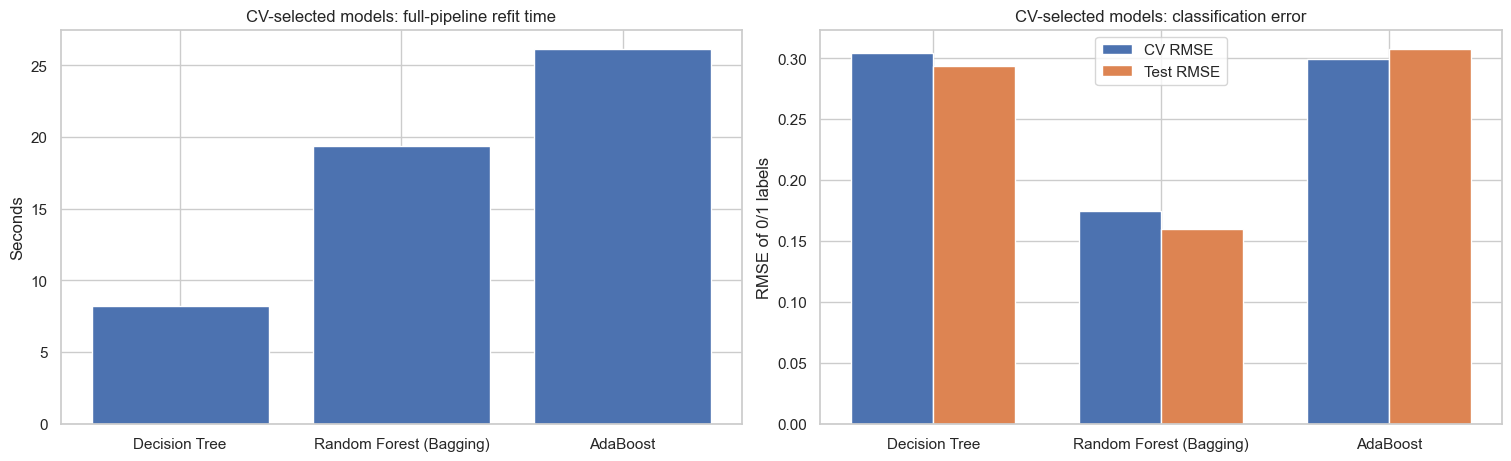

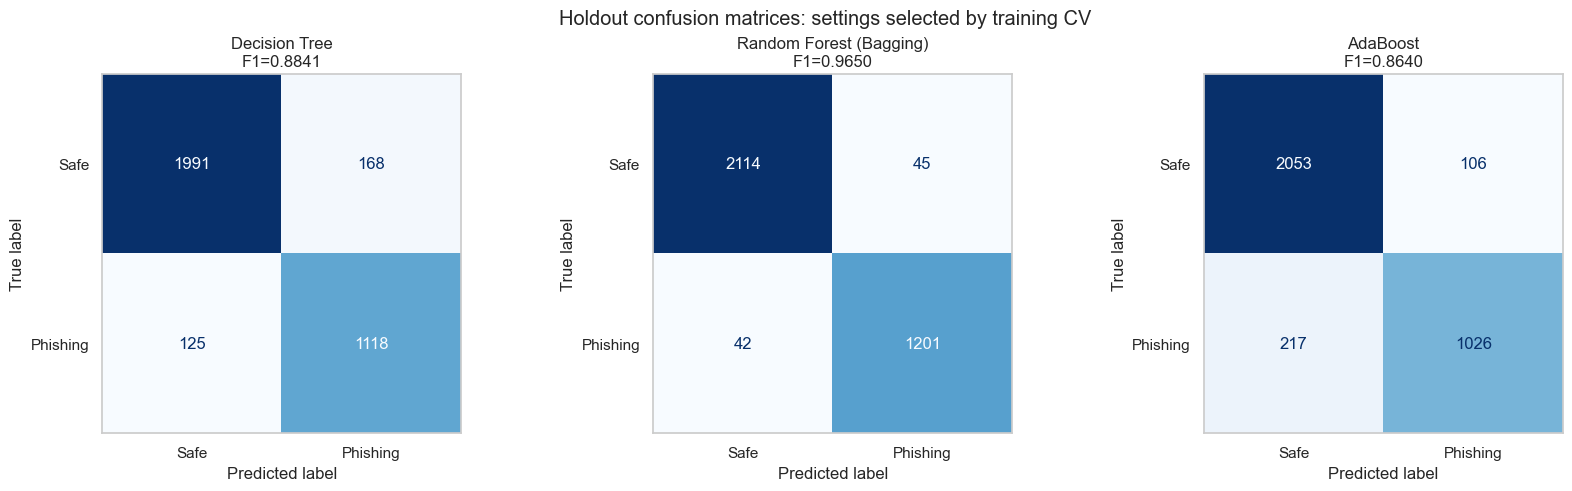

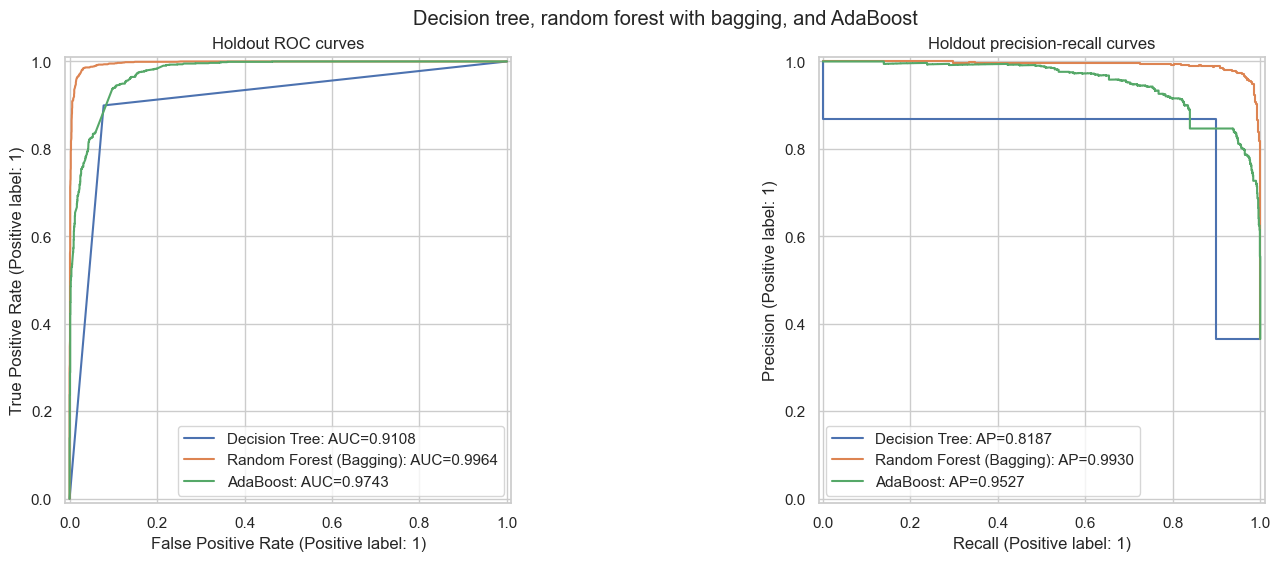

In [54]:
if holdout_results:
    # Compare full-training refit duration and classification error for the three winners.
    chart = holdout_results_df.set_index('model').loc[MODELS_TO_RUN]
    positions = np.arange(len(chart))
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), constrained_layout=True)
    axes[0].bar(positions, chart['Fit_Time_Seconds'])
    axes[0].set(title='CV-selected models: full-pipeline refit time', ylabel='Seconds')
    axes[1].bar(positions - 0.18, chart['CV_RMSE'], width=0.36, label='CV RMSE')
    axes[1].bar(positions + 0.18, chart['Test_RMSE'], width=0.36, label='Test RMSE')
    axes[1].set(title='CV-selected models: classification error', ylabel='RMSE of 0/1 labels')
    axes[1].legend()
    for ax in axes:
        ax.set_xticks(positions, chart.index)
    if SAVE_MODEL_ARTIFACTS:
        fig.savefig(RESULTS_DIR / 'selected_error_and_fit_time.png', dpi=150, bbox_inches='tight')
    plt.show()

    # Same holdout rows and label ordering for every confusion matrix.
    fig, axes = plt.subplots(1, len(MODELS_TO_RUN), figsize=(5.5 * len(MODELS_TO_RUN), 4.8),
                             constrained_layout=True, squeeze=False)
    for ax, name in zip(axes.flat, MODELS_TO_RUN):
        result = holdout_results[name]
        ConfusionMatrixDisplay(result['confusion_matrix'], display_labels=['Safe', 'Phishing']).plot(
            ax=ax, cmap='Blues', colorbar=False, values_format='d')
        ax.grid(False)
        ax.set_title(f"{name}\nF1={result['metrics']['f1']:.4f}")
    fig.suptitle('Holdout confusion matrices: settings selected by training CV')
    if SAVE_MODEL_ARTIFACTS:
        fig.savefig(RESULTS_DIR / 'confusion_matrices.png', dpi=160, bbox_inches='tight')
    plt.show()

    # Ranking plots reuse stored positive-class probabilities; no models are refitted.
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True)
    for name in MODELS_TO_RUN:
        result = holdout_results[name]
        RocCurveDisplay.from_predictions(y_test, result['probability_scores'], ax=axes[0], name=name)
        PrecisionRecallDisplay.from_predictions(y_test, result['probability_scores'], ax=axes[1], name=name)
    axes[0].legend([f"{name}: AUC={holdout_results[name]['metrics']['roc_auc']:.4f}" for name in MODELS_TO_RUN],
                   loc='lower right')
    axes[1].legend([f"{name}: AP={holdout_results[name]['metrics']['average_precision']:.4f}" for name in MODELS_TO_RUN],
                   loc='lower left')
    axes[0].set_title('Holdout ROC curves')
    axes[1].set_title('Holdout precision-recall curves')
    fig.suptitle('Decision tree, random forest with bagging, and AdaBoost')
    if SAVE_MODEL_ARTIFACTS:
        fig.savefig(RESULTS_DIR / 'roc_precision_recall.png', dpi=160, bbox_inches='tight')
    plt.show()


### Observations on classification perfromance on the holdout set with Random Forest, Decission Tress and Adaboost algorithm:

On the shared holdout set of **3,402 emails**, I observe that **Random Forest with 300 trees achieves the strongest classification performance**. It has the highest accuracy, phishing F1, ROC-AUC, and average precision, together with the lowest classification RMSE.

For **Random Forest**, holdout accuracy is **97.44%**, precision is **96.39%**, recall is **96.62%**, and F1 is **0.9650**. The confusion matrix shows **1,201 correctly detected phishing emails**, with only **42 missed phishing emails and 45 legitimate emails incorrectly flagged**. Its strong precision and recall indicate that it successfully limits both types of error. Its holdout F1 is also close to its CV F1 of **0.9591**, showing consistent performance across these evaluations.

For the **Decision Tree**, accuracy is **91.39%** and F1 is **0.8841**. It correctly identifies **1,118 phishing emails**, but misses **125** and incorrectly flags **168 legitimate emails**. Its recall of **89.94%** is higher than AdaBoost’s, but its lower precision of **86.94%** reflects more false alarms. The Decision Tree is the fastest model to fit, taking approximately **8.24 seconds**, although this speed comes with substantially more classification errors than Random Forest.

For **AdaBoost**, accuracy is **90.51%** and F1 is **0.8640**. Its precision of **90.64%** exceeds the Decision Tree’s, and it produces fewer false alarms: **106 compared with 168**. However, its recall falls to **82.54%**, resulting in **217 missed phishing emails**, the highest number among the three models. At the prediction rule used here, AdaBoost therefore reduces false alarms relative to the Decision Tree while missing more phishing messages. It also has the longest fit time, approximately **26.18 seconds**, compared with **19.35 seconds** for Random Forest.

The **ROC and precision–recall curves** reinforce Random Forest’s strong performance, with **ROC-AUC of 0.9964 and average precision of 0.9930**. AdaBoost ranks second on these measures, with **0.9743 and 0.9527**, despite having the lowest F1. This distinction shows that AdaBoost ranks emails relatively well by their scores, but its standard classification rule produces a less favorable precision–recall balance. The Decision Tree has weaker ranking performance, with **ROC-AUC of 0.9108 and average precision of 0.8187**.

The error plot also favors Random Forest: its holdout RMSE is **0.1599**, compared with **0.2935 for Decision Tree** and **0.3081 for AdaBoost**. CV and holdout results are broadly similar, without a large deterioration on this holdout set. Because the holdout has been used previously, I interpret these comparisons as exploratory.

## 16. Hyperparameter plots for each model family

For each family, reuse candidate CV scores to plot mean F1, label RMSE, and mean
fold-fit time. Labels show the parameters that vary in the chosen grid; the
factory definitions specify the fixed settings. The star marks the same CV-F1
winner printed in the results section. Error bars show **fold standard deviation**,
not confidence intervals. Training F1 appears when its collection is enabled.
No candidate is retrained just to draw these figures.

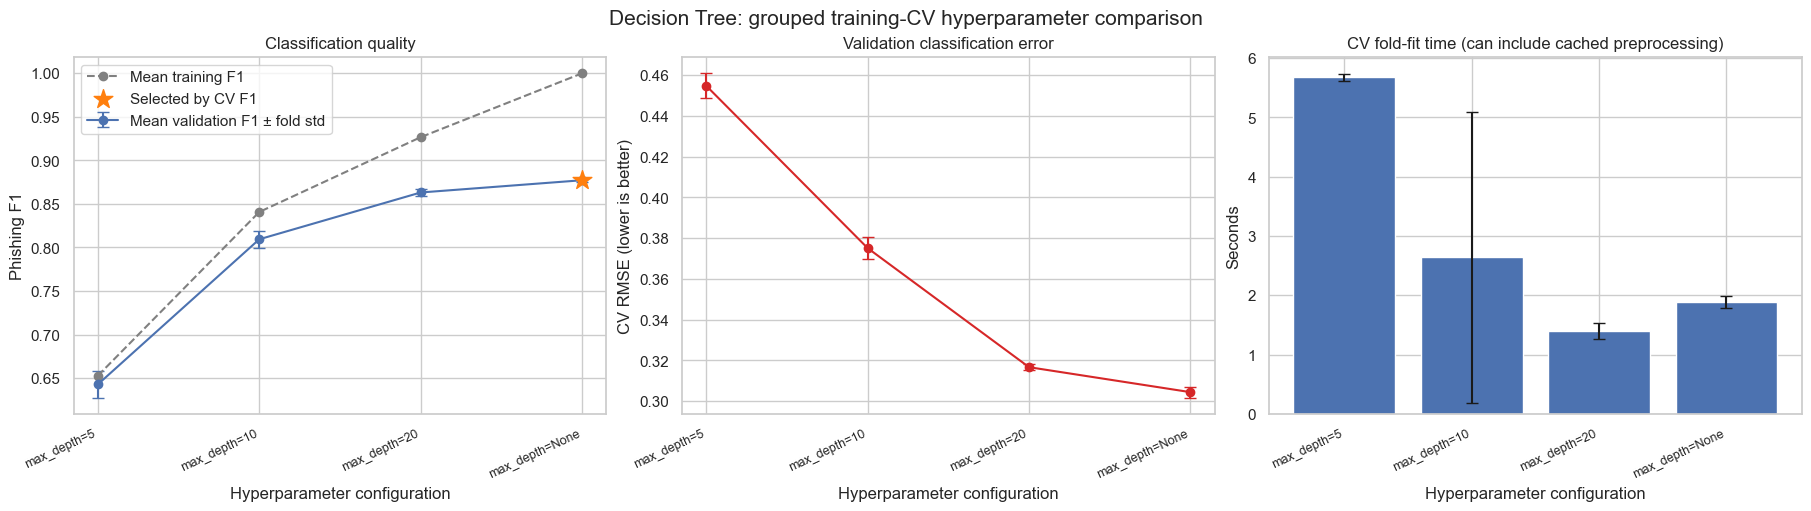

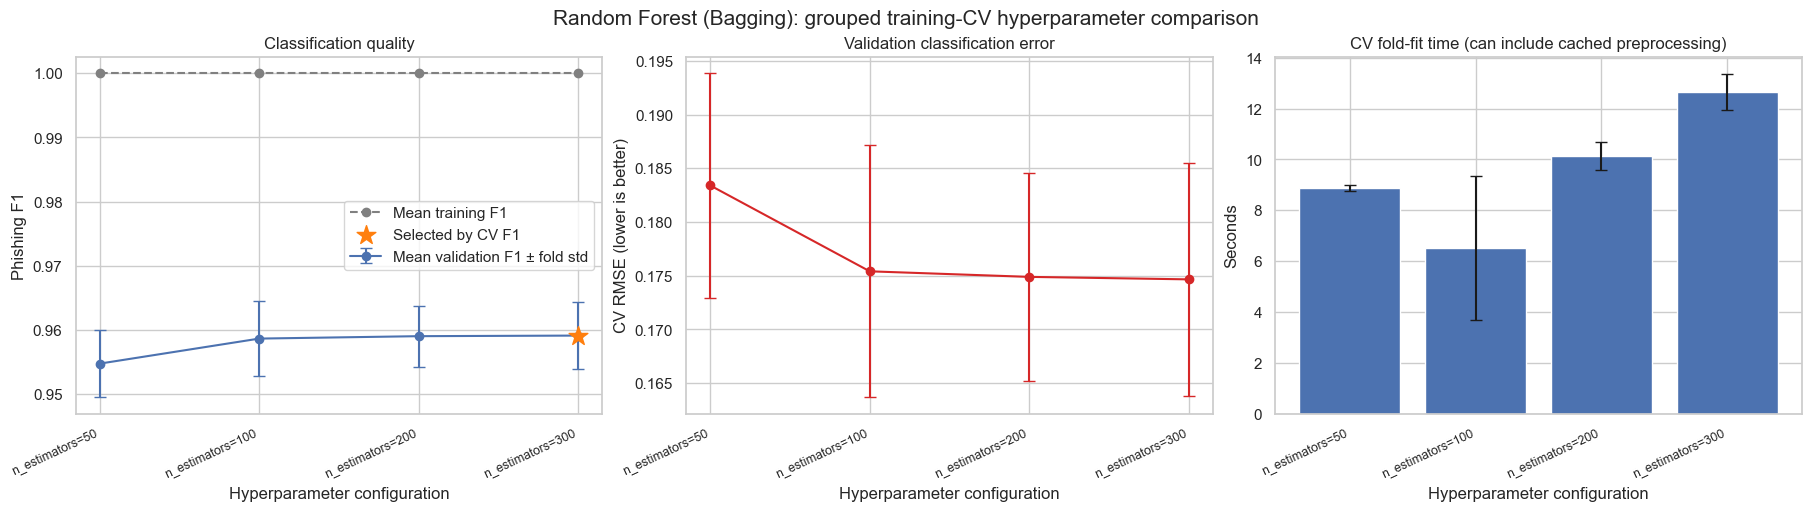

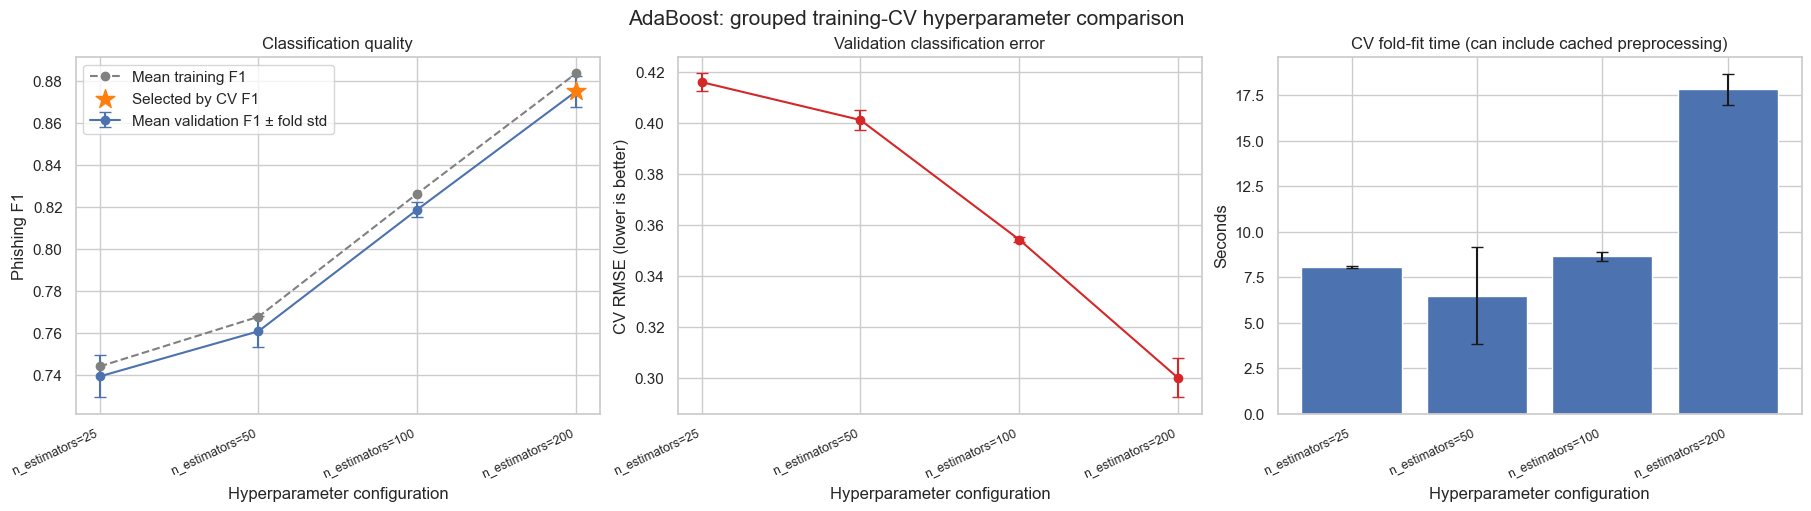

In [55]:
for model_name, search in model_searches.items():
    cv = model_cv_frames[model_name]
    positions = np.arange(len(cv))
    varying_keys = [key for key, values in param_grids[model_name].items() if len(values) > 1]
    labels = ['\n'.join(f'{key.removeprefix("model__")}={parameters[key]}'
                         for key in varying_keys) for parameters in cv['params']]
    fig, axes = plt.subplots(1, 3, figsize=(max(18, len(cv) * 2), 5), constrained_layout=True)
    axes[0].errorbar(positions, cv['mean_test_f1'], yerr=cv['std_test_f1'],
                     fmt='o-', capsize=4, label='Mean validation F1 ± fold std')
    if 'mean_train_f1' in cv:
        axes[0].plot(positions, cv['mean_train_f1'], 'o--', color='gray', label='Mean training F1')
    axes[0].scatter(search.best_index_, search.best_score_, marker='*', s=200,
                    color='tab:orange', zorder=5, label='Selected by CV F1')
    axes[0].set(title='Classification quality', ylabel='Phishing F1')
    axes[0].legend(loc='best')
    axes[1].errorbar(positions, -cv['mean_test_rmse'], yerr=cv['std_test_rmse'],
                     fmt='o-', color='tab:red', capsize=4)
    axes[1].set(title='Validation classification error', ylabel='CV RMSE (lower is better)')
    axes[2].bar(positions, cv['mean_fit_time'], yerr=cv['std_fit_time'], capsize=4)
    axes[2].set(title='CV fold-fit time (can include cached preprocessing)', ylabel='Seconds', ylim=(0, None))
    for ax in axes:
        ax.set_xticks(positions, labels, fontsize=9, rotation=25, ha='right')
        ax.set_xlabel('Hyperparameter configuration')
    fig.suptitle(f'{model_name}: grouped training-CV hyperparameter comparison', fontsize=15)
    if SAVE_MODEL_ARTIFACTS:
        fig.savefig(RESULTS_DIR / f'{MODEL_FILE_STEMS[model_name]}_hyperparameters.png', dpi=150, bbox_inches='tight')
    plt.show()


## 17. Comments on hyperparameter tuning and classification performance
Across the three sets of graphs, I observe that **Random Forest provides the strongest validation performance**, with phishing F1 close to **0.96** and CV RMSE around **0.175**. The Decision Tree and AdaBoost achieve lower validation F1 scores, although both improve as their complexity increases. The values below are approximate readings from the graphs.

For the **Decision Tree**, increasing maximum depth from 5 to unrestricted raises validation F1 from approximately **0.64 to 0.88**, while RMSE falls from about **0.45 to 0.30**. The shallow tree appears to underfit, and allowing greater depth improves its performance. However, training F1 reaches **1.00**, while validation F1 remains around **0.88**. This widening gap suggests increasing overfitting, even though validation performance continues to improve. The unrestricted tree is the best configuration tested for this model, but its perfect training score does not carry over to the validation folds.

For the **Random Forest**, validation F1 improves from approximately **0.955 with 50 trees to 0.959 with 300 trees**. Most of this improvement occurs between 50 and 100 trees, after which both F1 and RMSE largely stabilize. Training F1 remains near **1.00**, with a smaller training–validation gap than the unrestricted Decision Tree. Although 300 trees has the highest mean validation F1, its advantage over 100 and 200 trees is very small, and their fold error bars overlap. Meanwhile, measured fit time rises from approximately **6.5 seconds at 100 trees to 12.5 seconds at 300 trees**, showing diminishing performance gains for the additional computation.

For **AdaBoost**, increasing the number of estimators from 25 to 200 produces a steady improvement: validation F1 rises from approximately **0.74 to 0.875**, and RMSE decreases from about **0.42 to 0.30**. Training and validation F1 remain close throughout, showing less apparent overfitting than the deeper Decision Trees. Unlike Random Forest, AdaBoost still shows a noticeable improvement between its final two configurations. However, fit time roughly doubles from **9 seconds at 100 estimators to 18 seconds at 200 estimators**, while its validation F1 remains below Random Forest.

These are cross-validation results rather than holdout results. The timing plots also include substantial variation for some configurations and may include preprocessing costs, so the runtime differences should be interpreted cautiously.